# Día 3 — Clasificación: árbol, bosque, KNN y SVM

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Del número a una clase y de una clase a una decisión. Hoy usamos **tres datasets financieros, cada uno elegido para explicar mejor un algoritmo**: un árbol se entiende mejor con transacciones que se separan por tipo, monto y hora; KNN con clientes que se parecen por su comportamiento, y SVM con préstamos que se separan por ingreso y tasa.

## Objetivos de aprendizaje

- Definir un problema de clasificación binaria y el momento en que se hace la predicción.
- Explicar desbalance, baseline, nodo/hoja e impureza Gini antes de ajustar un árbol.
- Construir una matriz de confusión e interpretar Accuracy, Precision, Recall y F1.
- Entender cómo deciden un árbol, un bosque, KNN y SVM, y qué hiperparámetros controlan cada uno.
- Detectar fugas de información y distinguir los resultados de un dataset de los de un algoritmo.
- Elegir una estrategia según los errores que importan y reservar Test para el final.

## Los tres conjuntos de datos del día

| Parte | Dataset (archivo en `datos/`) | Pregunta sí/no | Filas | % clase positiva | Algoritmo que explica |
|---|---|---|---:|---:|---|
| A | PaySim (`paysim_muestra.csv`, muestra de `bank_risk_pay.csv`) | ¿La transacción es fraude? | 100 198 (de 6 362 620) | 8,2 % en la muestra (0,13 % real) | Árbol y Random Forest |
| B | BankChurners (`BankChurners.csv`) | ¿El cliente abandonó la tarjeta de crédito? | 10 127 | 16,1 % | KNN |
| C | Credit Risk (`credit_risk_dataset.csv`) | ¿El préstamo cayó en impago? | 32 581 | 21,8 % | SVM |

### Los tres datasets en pocas palabras

**PaySim (fraude en dinero móvil).** Cada fila es una transacción de un servicio de dinero móvil simulado: su tipo (transferencia, retiro, pago…), su monto y la hora en que ocurrió. Queremos saber si la transacción es **fraude**. Lo usamos para el **árbol de clasificación** porque con tres variables (tipo, monto y hora) el árbol hace preguntas fáciles de leer, y para aprender a leer la **matriz de confusión** y las métricas nuevas.

**BankChurners (abandono de tarjetas).** Cada fila es un cliente de tarjeta de crédito con su comportamiento del último año: cuántas transacciones hizo, cuánto gastó, cuánto usa de su límite, cuántos meses estuvo inactivo. Queremos saber si el cliente **abandonó** la tarjeta. Lo usamos para **KNN** porque la idea de «buscar clientes parecidos» es natural con datos de comportamiento.

**Credit Risk (impago de préstamos).** Cada fila es un préstamo aprobado: ingreso y edad de la persona, monto, tasa de interés, grado de riesgo e historial crediticio. Queremos saber si el préstamo **cayó en impago**. Lo usamos para **SVM** porque los préstamos pagados e impagos se separan bastante bien por la tasa y por la proporción del ingreso que representa el préstamo, y así se puede dibujar la frontera.

Cada parte empieza con la descripción completa de su dataset. Fuentes, advertencias y licencias están en `datos/README.md`. **Ninguno describe clientes del Ecuador ni del BCE**, y PaySim es sintético.

## Antes de empezar: ¿qué es un problema de clasificación?

En aprendizaje supervisado tenemos ejemplos del pasado. Cada ejemplo contiene datos de entrada —que llamamos X— y una respuesta conocida —que llamamos y—. Entrenamos un modelo con esos ejemplos para que, al recibir una fila nueva, estime una respuesta.

<p align="center">
    <img src="../material_apoyo/classification.png" width="350">
</p>

La primera pregunta es: ¿qué tipo de respuesta queremos obtener?

- En regresión, la respuesta es una cantidad numérica. Por ejemplo: «¿cuánto crecerá el PIB?». Nos importa qué tan lejos está la predicción del valor real.
- En clasificación, la respuesta es una categoría. Por ejemplo: «¿esta transacción es fraude?», «¿el cliente abandonará la tarjeta?», «¿el préstamo caerá en impago?». El modelo debe asignar una clase a cada fila nueva.

Los datos de entrada podrían parecerse; lo que define el tipo de problema es la respuesta que queremos predecir. Hoy haremos **clasificación binaria**: dos clases. Llamaremos **clase positiva** (codificada como 1) a la que queremos detectar: fraude, abandono o impago. «Positiva» no significa «buena» ni implica que el modelo esté seguro: es el nombre de la clase de interés.

Un clasificador no conoce por sí solo el costo de equivocarse. Por eso no bastará con contar aciertos: examinaremos qué tipos de errores comete. También debemos definir **cuándo** se usará la predicción: solo pueden entrar al modelo datos disponibles en ese momento. Usar información que se conoce después sería darle una pista del futuro: una **fuga de información**.

### Nuestro problema: identificar transacciones sospechosas

Imaginemos que tenemos información histórica de operaciones financieras:

| Operación | Tipo | Monto USD | Saldo anterior USD | ¿Fraude? (`isFraud`) |
|---|---|---:|---:|---|
| 1 | PAYMENT | 50 | 800 | No (0) |
| 2 | TRANSFER | 8 000 | 8 000 | **Sí (1)** |
| 3 | CASH_OUT | 100 | 1 500 | No (0) |
| 4 | TRANSFER | 5 000 | 5 000 | **Sí (1)** |
| 5 | PAYMENT | 30 | 300 | No (0) |

Cada fila es una transacción. Las columnas describen sus **características** (X) e `isFraud` es la **variable objetivo** (y): 0 = transacción legítima, 1 = transacción fraudulenta. El árbol intentará aprender reglas para distinguir ambos grupos.

**¿Qué es una clase?** Cada valor posible de la variable objetivo. Aquí hay dos clases: 0 (legítima) y 1 (fraude). La que queremos detectar es la **clase positiva** (1); la otra, la negativa (0). Con dos clases el problema es **binario**; con tres o más (por ejemplo, segmento A, B o C) sería **multiclase**.

**Regresión y clasificación: qué cambia**

| | Regresión (Días 1 y 2) | Clasificación (hoy) |
|---|---|---|
| Pregunta | ¿Cuánto? | ¿Cuál clase? ¿sí o no? |
| Respuesta | un número: 3 109 USD, 2,4 % | una etiqueta: fraude / normal |
| El error es… | una distancia | un acierto o un fallo |
| Métricas | MAE, RMSE, R² | matriz de confusión, Precision, Recall, F1 |
| Hoja del árbol | el promedio de y | la clase más frecuente |
| Criterio para cortar | reducir el SSE | reducir el índice Gini |
| Modelo de referencia | predecir el promedio | predecir la clase más frecuente |

**Dos momentos distintos.** Hoy veremos dos conceptos fundamentales del árbol de clasificación. El **índice de Gini** responde «¿cómo decide el árbol qué pregunta hacer para separar las transacciones?» y se usa con Train, para **construir** el árbol. La **matriz de confusión** responde «una vez entrenado, ¿cómo sabemos si detecta correctamente los fraudes?» y se usa con Validation, para **evaluar** sus predicciones.

### Una clase no es lo mismo que una probabilidad

Si el modelo responde `fraude` para una transacción, significa: «según la regla de decisión del modelo, esta transacción pertenece a la clase de las fraudulentas». No significa certeza. Del mismo modo, `no fraude` no significa que sea imposible.

Algunos clasificadores calculan primero un valor intermedio o **score**: una señal que ayuda a situar la fila de un lado u otro de la frontera de decisión. Un score mayor puede indicar más evidencia a favor de la clase positiva, pero no debemos leerlo automáticamente como una probabilidad. Una **regla de decisión** convierte esa señal en clase: si hacemos más fácil asignar la clase positiva, detectaremos más casos, pero también emitiremos más falsas alarmas.

### Error de clasificación y decisiones económicas

Imaginemos dos transacciones. A la primera, el modelo la marca como fraude y la bloqueamos, pero era legítima: un **falso positivo** (molestamos a un cliente). A la segunda, el modelo dice que es normal, pero era fraude: un **falso negativo** (perdimos dinero).

No siempre conviene reducir ambos errores de la misma manera. Si revisar una alerta cuesta poco y un fraude cuesta mucho, aceptaremos más falsas alarmas para encontrar más fraudes: nos importará el **Recall** («de los fraudes reales, ¿cuántos encontramos?»). Si cada alerta exige mucho trabajo, nos importará la **Precision** («de lo que marcamos, ¿cuánto era fraude?»). El algoritmo no decide por nosotros cuánto vale cada error.

# 0. Librerías

Las librerías utilizadas forman parte de una instalación habitual de Anaconda / scikit-learn.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# En algunos Windows/Anaconda, joblib no logra contar núcleos físicos; esto no cambia resultados.
_ = os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

### Ubicación de los datos

Jupyter interpreta las rutas relativas desde su **directorio de trabajo actual**, no desde la ubicación del archivo `.ipynb`. Si se ejecuta desde la raíz del proyecto, el CSV está en `datos/`; si se ejecuta desde `notebooks/`, está en `../datos/`. La celda siguiente elige entre esas dos ubicaciones sin definir una función.

In [2]:
# Sirve si Jupyter se inició desde modulo3_ml/ o desde modulo3_ml/notebooks/.
DATA_DIR = Path("../datos")
if not DATA_DIR.exists():
    DATA_DIR = Path("datos")
ARCHIVO_PAY = DATA_DIR / "paysim_muestra.csv"
ARCHIVO_CHURN = DATA_DIR / "BankChurners.csv"
ARCHIVO_CREDIT = DATA_DIR / "credit_risk_dataset.csv"
for archivo in [ARCHIVO_PAY, ARCHIVO_CHURN, ARCHIVO_CREDIT]:
    print("Encontrado" if archivo.exists() else "FALTA", "→", archivo.resolve())

Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\paysim_muestra.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\BankChurners.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\credit_risk_dataset.csv


## Herramientas comunes para medir

Las mismas dos funciones medirán los tres datasets. `resumen` calcula Accuracy, Precision, Recall y F1 de la clase positiva (siempre `1`); `conteos` muestra las cuatro casillas de la matriz de confusión. Las explicaremos con detalle en la Parte A, al ver la primera matriz.

In [3]:
def resumen(y_real, y_pred, nombre):
    # y_real siempre contiene clases reales; y_pred, las predicciones del modelo.
    return {"modelo": nombre,
            "accuracy": accuracy_score(y_real, y_pred),
            "precision_pos": precision_score(y_real, y_pred, zero_division=0),
            "recall_pos": recall_score(y_real, y_pred, zero_division=0),
            "f1_pos": f1_score(y_real, y_pred, zero_division=0)}

def conteos(y_real, y_pred, nombre):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {"modelo": nombre, "VN": vn, "FP": fp, "FN": fn, "VP": vp, "alertas": vp + fp}

# Parte A · PaySim: árbol de clasificación y Random Forest para detectar fraude

## A.1 El problema y el dataset

**El problema.** En un servicio de dinero móvil, el equipo de riesgo quiere marcar a tiempo las transacciones fraudulentas. Cada transacción es `fraude` (1) o `no fraude` (0): una clasificación binaria donde la clase positiva es el fraude.

**Contexto.** Hay pocos datasets públicos de servicios financieros, sobre todo de transacciones de dinero móvil, y son muy importantes para investigar la detección de fraude. Parte del problema es la naturaleza privada de las transacciones financieras. Por eso los autores presentan un **dataset sintético** generado con el simulador **PaySim**: usa datos agregados de un dataset privado para generar transacciones que se parecen a la operación normal e **inyecta comportamiento malicioso** para evaluar métodos de detección de fraude.

**Contenido.** PaySim simula transacciones de dinero móvil a partir de una muestra de transacciones reales de **un mes** de registros de un servicio implementado en un país africano. Los registros originales los entregó una empresa multinacional que ofrece ese servicio financiero en más de 14 países. La versión de Kaggle está reducida a 1/4 del original: **6 362 620 transacciones**, de las cuales **8 213 son fraude (0,13 %)**. En nuestra carpeta es el archivo `datos/bank_risk_pay.csv`.

| Columna | Qué es | ¿Entra al modelo? | Por qué |
|---|---|---|---|
| `step` | Hora de la simulación: 1 step = 1 hora; 744 steps ≈ 30 días | Sí, convertida en **hora del día** | El fraude se concentra de madrugada |
| `type` | Tipo de transacción (5 tipos, ver abajo) | Sí, resumida en `transfer_o_retiro` | El fraude solo usa `TRANSFER` y `CASH_OUT` |
| `amount` | Monto de la transacción en moneda local | Sí | Los fraudes suelen ser montos altos |
| `nameOrig` / `nameDest` | Código del cliente que envía / recibe | No | Es un nombre, no una característica: no se repite en clientes nuevos |
| `oldbalanceOrg` / `newbalanceOrig` | Saldo del que envía, antes / después | No | Fuga de información (ver abajo) |
| `oldbalanceDest` / `newbalanceDest` | Saldo del que recibe, antes / después (vacío para comercios, que empiezan con M) | No | Fuga de información |
| `isFlaggedFraud` | Alerta de la regla actual del negocio: marca todo intento de transferir más de 200 000 en una sola transacción | No; la usamos para **comparar** | Es la respuesta de otro detector |
| `isFraud` | Transacción hecha por los agentes fraudulentos de la simulación: toman el control de una cuenta, **transfieren** el saldo a otra cuenta y luego lo **retiran en efectivo** | Es la **y** (target) | Lo que queremos predecir |

**Los cinco tipos de transacción (`type`).**

| Tipo | Qué es |
|---|---|
| `CASH_IN` | El cliente entrega efectivo en un comercio o agente y le cargan saldo en su billetera |
| `CASH_OUT` | Lo contrario: retira efectivo de su billetera |
| `DEBIT` | Parecido a `CASH_OUT`, pero el dinero va de la billetera a una cuenta bancaria |
| `PAYMENT` | Pago de bienes o servicios a un comercio |
| `TRANSFER` | Envío de dinero a otro usuario de la plataforma |

**¿Para qué sirve `step`?** Cuenta las horas desde el inicio de la simulación: step 1 es la primera hora del día 1 y step 25 la primera hora del día 2. Tal cual no sirve para predecir, porque una «hora 600 del mes» no se repite en el futuro. Lo útil es la **hora del día**: el resto de dividir `step` para 24. Por ejemplo, step 27 = día 2 a las 3 de la mañana (27 − 24 = 3); step 110 = día 5 a las 14 h (110 − 96 = 14). Transformar una columna con conocimiento del negocio se llama **ingeniería de variables**.

**¿Por qué no usamos `isFlaggedFraud` como variable?** No describe la transacción: es la salida de la regla que ya existe. Además casi nunca se activa (en la muestra, 16 veces, aunque hubo 2 740 transferencias fraudulentas de más de 200 000). Si la metiéramos, el modelo copiaría una regla que casi nunca avisa. La usaremos como **rival**: ¿nuestro modelo le gana a la regla actual?

**¿Por qué quitamos los saldos? Fuga de información.** Una fuga ocurre cuando el modelo usa una columna que contiene la respuesta o que se escribió conociéndola: el modelo parece excelente en clase y falla en la vida real. *Analogía:* predecir si un estudiante aprobará usando su «nota final»; acierta siempre, pero esa nota solo existe cuando ya se sabe si aprobó. En PaySim el propio dataset advierte que **las transacciones detectadas como fraude se cancelan**, y la cancelación altera las cuatro columnas de saldo: los saldos llevan la huella del resultado. Por eso, para detectar fraude **no se deben usar** `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest` ni `newbalanceDest`. En A.3 comprobaremos que con ellas el modelo parece «demasiado bueno».

**Cita:** E. A. Lopez-Rojas, A. Elmir y S. Axelsson, «PaySim: A financial mobile money simulator for fraud detection», 28th European Modeling and Simulation Symposium (EMSS), Lárnaca, Chipre, 2016. Más detalles en la tesis doctoral de Lopez-Rojas, capítulo 7 (<http://urn.kb.se/resolve?urn=urn:nbn:se:bth-12932>).

**Por qué lo usamos para árboles.** Con pocas variables (tipo, monto y hora) el árbol hace preguntas fáciles de leer, la matriz de confusión se entiende como «fraudes detectados frente a falsas alarmas» y el índice Gini se puede calcular a mano.

## A.2 La muestra de clase

El archivo completo pesa cerca de 500 MB: tarda en cargarse y supera el límite de 100 MB por archivo de GitHub. Además, con 0,13 % de fraudes, una muestra al azar de 100 000 filas tendría solo unos 130 fraudes. Por eso trabajamos con `datos/paysim_muestra.csv`, que contiene **todos los 8 213 fraudes** y una muestra aleatoria de **91 985 transacciones normales** (cerca del 1,45 % de ellas).

**Esto cambia la tasa base:** en la muestra el fraude es 8,2 %, no 0,13 %. Quitar parte de la clase mayoritaria es una técnica para trabajar con datos desbalanceados que se llama **submuestreo**. Sirve para aprender, pero en la población real muchas más alertas serían falsas y la Precision sería mucho menor.

### Datasets balanceados y desbalanceados

Un dataset está **balanceado** cuando las clases tienen tamaños parecidos (por ejemplo, 500 normales y 500 fraudes). Está **desbalanceado** cuando una clase es mucho más frecuente (por ejemplo, 980 normales y 20 fraudes). Los tres datasets del día son desbalanceados: 8 % de fraudes en la muestra de PaySim (0,13 % en el archivo real), 16 % de abandonos en BankChurners y 22 % de impagos en Credit Risk.

**¿Por qué es un problema?** Muchos algoritmos intentan equivocarse lo menos posible **en total**. Con 980 normales y 20 fraudes, un modelo que diga siempre «normal» acierta el 98 % y no detecta ningún fraude. El modelo aprende poco de la clase minoritaria, que es justamente la que nos interesa, y la Accuracy queda alta aunque el modelo no sirva.

**Cómo trabajar para que no sea un impedimento:**

1. **Dividir con `stratify`** (o por grupos, como haremos aquí) para que Train, Validation y Test conserven la proporción de clases.
2. **Medir con las métricas correctas:** Precision, Recall y F1 de la clase minoritaria, nunca solo Accuracy (A.6 y A.7).
3. **Pesar las clases (`class_weight="balanced"`):** cada error en la clase minoritaria cuenta más durante el entrenamiento. No cambia los datos.
4. **Submuestreo (*undersampling*):** quitar filas de la clase mayoritaria **en Train**. Es lo que hicimos al crear `paysim_muestra.csv`. Rápido, pero se pierde información.
5. **Sobremuestreo (*oversampling*):** repetir filas de la clase minoritaria **en Train** (o crear filas sintéticas parecidas, como hace SMOTE de la librería `imbalanced-learn`). No se pierde información, pero el modelo puede memorizar las filas repetidas.
6. **Mover el umbral** de decisión (Parte D).

**Regla de oro:** se balancea **solo Train**. Validation y Test deben conservar la proporción real, porque representan los datos que llegarán de verdad. En A.8 probaremos estas estrategias con el mismo árbol.

In [4]:
pay = pd.read_csv(ARCHIVO_PAY)
print("Dimensiones de la muestra:", pay.shape)
print("Fraudes:", int(pay["isFraud"].sum()), "| Proporción de fraude en la muestra:", round(pay["isFraud"].mean() * 100, 2), "%")
print("Nulos en todo el archivo:", int(pay.isna().sum().sum()))
pd.crosstab(pay["type"], pay["isFraud"], margins=True)

Dimensiones de la muestra: (100198, 11)
Fraudes: 8213 | Proporción de fraude en la muestra: 8.2 %
Nulos en todo el archivo: 0


isFraud,0,1,All
type,,,
CASH_IN,20051,0,20051
CASH_OUT,32471,4116,36587
DEBIT,593,0,593
PAYMENT,31018,0,31018
TRANSFER,7852,4097,11949
All,91985,8213,100198


**Lee la tabla.** Todos los fraudes ocurren en **dos tipos**: `TRANSFER` (4 097) y `CASH_OUT` (4 116). Coincide con la descripción del dataset: el fraude consiste en transferir a otra cuenta y luego retirar. Con ese conocimiento del negocio creamos una columna sencilla, `transfer_o_retiro` (1 si el tipo es `TRANSFER` o `CASH_OUT`).

Miremos también el monto y la hora del día (`hora = step % 24`, porque cada step es una hora).

Monto mediano — normal: 75617 | fraude: 441423


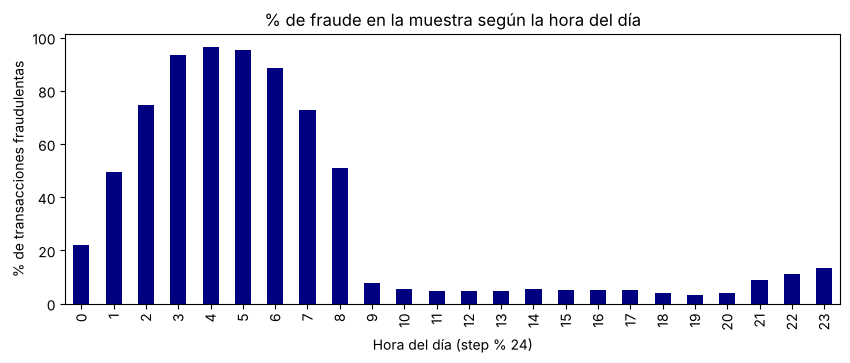

In [5]:
pay["hora"] = pay["step"] % 24
pay["transfer_o_retiro"] = pay["type"].isin(["TRANSFER", "CASH_OUT"]).astype(int)
print("Monto mediano — normal:", round(pay.loc[pay.isFraud == 0, "amount"].median()),
      "| fraude:", round(pay.loc[pay.isFraud == 1, "amount"].median()))

fraude_hora = pay.groupby("hora")["isFraud"].mean() * 100
fraude_hora.plot(kind="bar", figsize=(10, 3.5), color="navy", title="% de fraude en la muestra según la hora del día")
plt.ylabel("% de transacciones fraudulentas"); plt.xlabel("Hora del día (step % 24)")
plt.show()

**Interpretación.** El monto mediano de un fraude es mucho mayor que el de una transacción normal (unos 441 000 frente a 76 000). Y entre las 2 y las 7 de la mañana la mayoría de transacciones de la muestra son fraude: en la simulación, los defraudadores operan a cualquier hora, mientras que la actividad normal se concentra durante el día. Un árbol puede aprovechar ambas cosas con pocas preguntas. **Cuidado:** es un dataset sintético y una muestra enriquecida; no describe fraudes en el Ecuador.

## A.3 Variables, división y una fuga escondida

Usamos **tres variables**: `transfer_o_retiro`, `amount` y `hora`. Quedan fuera los identificadores (`nameOrig`, `nameDest`), las cuatro columnas de saldo (fuga) e `isFlaggedFraud`, que es una regla del negocio y usaremos como referencia.

**Cada fraude aparece dos veces.** El defraudador primero transfiere (`TRANSFER`) y luego retira (`CASH_OUT`) **el mismo monto, en la misma hora**. Si dividimos las filas al azar, a menudo una «pata» del fraude cae en Train y la otra en Validation: un árbol podría **memorizar el monto exacto** en Train y «reconocerlo» en Validation. Eso no es aprender a detectar fraude, es una fuga entre filas relacionadas. Comprobémoslo.

In [6]:
fraudes = pay[pay["isFraud"] == 1]
pares = fraudes.groupby(["step", "amount"]).size()
print("Fraudes:", len(fraudes), "| operaciones distintas (misma hora y monto):", len(pares),
      "| operaciones con dos filas:", int((pares == 2).sum()))

Fraudes: 8213 | operaciones distintas (misma hora y monto): 4080 | operaciones con dos filas: 4000


Casi todos los fraudes vienen en parejas. Por eso definimos una **operación**: las dos filas de un mismo fraude tienen el mismo identificador; cada transacción normal es su propia operación. Dividimos 70 / 15 / 15 **por operación** con `GroupShuffleSplit`, así las dos patas de un fraude siempre quedan juntas en Train, en Validation o en Test. La proporción de fraude ya no es idéntica en las tres partes, pero queda muy cerca del 8 %.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

pay["operacion"] = np.where(pay["isFraud"] == 1,
                            "f" + pay["step"].astype(str) + "_" + pay["amount"].astype(str),
                            "n" + pay.index.astype(str))
FEAT_PAY = ["transfer_o_retiro", "amount", "hora"]

corte1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
idx_train, idx_rest = next(corte1.split(pay, groups=pay["operacion"]))
train_pay, rest_pay = pay.iloc[idx_train], pay.iloc[idx_rest]
corte2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
idx_val, idx_test = next(corte2.split(rest_pay, groups=rest_pay["operacion"]))
val_pay, test_pay = rest_pay.iloc[idx_val], rest_pay.iloc[idx_test]

X_train_pay, y_train_pay = train_pay[FEAT_PAY], train_pay["isFraud"]
X_val_pay, y_val_pay = val_pay[FEAT_PAY], val_pay["isFraud"]
X_test_pay, y_test_pay = test_pay[FEAT_PAY], test_pay["isFraud"]
for nombre, parte in [("Train", train_pay), ("Validation", val_pay), ("Test", test_pay)]:
    print(f"{nombre}: {len(parte)} filas, {int(parte['isFraud'].sum())} fraudes ({parte['isFraud'].mean() * 100:.1f} %)")
print("Operaciones compartidas entre Train y Validation:", len(set(train_pay["operacion"]) & set(val_pay["operacion"])))

Train: 70126 filas, 5735 fraudes (8.2 %)
Validation: 15063 filas, 1283 fraudes (8.5 %)
Test: 15009 filas, 1195 fraudes (8.0 %)
Operaciones compartidas entre Train y Validation: 0


### La prueba de la fuga de saldos: demasiado bueno para ser verdad

Miremos la tabla de la introducción: en los fraudes, el **monto es igual al saldo anterior** (8 000 y 8 000; 5 000 y 5 000). ¿Pasa en PaySim? Y si le damos los cuatro saldos al mismo árbol, ¿qué ocurre? (Usamos `DecisionTreeClassifier`, que estudiaremos en A.5; aquí solo nos interesa el resultado.)

In [8]:
from sklearn.tree import DecisionTreeClassifier
SALDOS = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
fr = pay[pay["isFraud"] == 1]; no = pay[pay["isFraud"] == 0]
print(f"Fraudes con monto = saldo anterior: {(fr['amount'] == fr['oldbalanceOrg']).mean():.1%}")
print(f"Normales con monto = saldo anterior: {(no['amount'] == no['oldbalanceOrg']).mean():.1%}")
for nombre, cols in [("Sin saldos", FEAT_PAY), ("Con los cuatro saldos", FEAT_PAY + SALDOS)]:
    m = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42).fit(train_pay[cols], y_train_pay)
    print(f"{nombre}: F1 en Validation = {f1_score(y_val_pay, m.predict(val_pay[cols])):.3f}")

Fraudes con monto = saldo anterior: 97.8%
Normales con monto = saldo anterior: 0.0%
Sin saldos: F1 en Validation = 0.633


Con los cuatro saldos: F1 en Validation = 0.884


**Interpretación.** Una sola comparación (monto = saldo anterior) casi separa las clases, y con los saldos el F1 salta de cerca de 0,63 a cerca de 0,88. Ese salto no es inteligencia del modelo: es la huella de la simulación y de la cancelación de los fraudes detectados. **Señal de alarma:** cuando una columna vuelve casi perfecto a un modelo, primero pregúntate si esa columna existiría antes de conocer la respuesta. Seguimos **sin saldos**: un F1 honesto vale más que uno que no se repetirá con datos nuevos.

### ¿Por qué conservar Train, Validation y Test?

Imagina que estudias para un examen. **Train** son los ejercicios con los que practicas y aprendes reglas. **Validation** son ejercicios nuevos que utilizas para comparar estrategias: si pruebas muchas y escoges la que más acertó allí, Validation ya influyó en tu decisión. **Test** es el examen final, que mantienes cerrado hasta haber decidido qué estrategia usarás. Y como acabamos de ver, los ejercicios del examen no pueden ser copias de los de práctica: por eso separamos por operación.

Las tres variables son numéricas y no tienen faltantes, así que el árbol no necesita preparación: no hace falta escalar, porque «¿monto ≤ 200 000?» no cambia si cambiamos de unidades.

## A.4 Dos referencias antes del primer árbol

Un **baseline** es una regla intencionalmente simple contra la cual mediremos modelos más elaborados. Usaremos dos:

1. **Responder siempre «no fraude»** (`DummyClassifier`): acierta mucho porque el 92 % de la muestra es normal, pero no detecta ningún fraude.
2. **La regla del negocio `isFlaggedFraud`**: marca transferencias de más de 200 000 como intento ilegal.

In [9]:
baseline_pay = DummyClassifier(strategy="most_frequent").fit(X_train_pay, y_train_pay)
pred_base_pay = baseline_pay.predict(X_val_pay)
pred_regla_pay = val_pay["isFlaggedFraud"].to_numpy()
print("Frecuencia real en Validation:", y_val_pay.value_counts().sort_index().to_dict())
print("Predicciones del baseline:", pd.Series(pred_base_pay).value_counts().sort_index().to_dict())
print("Alertas de la regla isFlaggedFraud en Validation:", int(pred_regla_pay.sum()))

Frecuencia real en Validation: {0: 13780, 1: 1283}
Predicciones del baseline: {0: 15063}
Alertas de la regla isFlaggedFraud en Validation: 5


### Leer la salida de las referencias

La primera línea muestra la **realidad** en Validation: cuántas transacciones son normales y cuántas fraude. El baseline llama «no fraude» a todas: acertará cerca del 92 %, pero deja escapar **todos** los fraudes. La regla del negocio emite poquísimas alertas: casi nunca se equivoca cuando avisa, pero tampoco detecta casi nada. Las dos referencias muestran por qué contar aciertos no basta.

### Pausa de comprensión

De cada 100 transacciones de la muestra, imagina 92 normales y 8 fraudes. Si dices «no fraude» a todas: ¿cuántas aciertas?, ¿cuántos fraudes encuentras? Si bloquear una transacción legítima molesta al cliente y dejar pasar un fraude cuesta dinero, ¿qué error preferirías evitar?

## A.5 Árbol de clasificación: aprender preguntas, no una sola fórmula

Piensa en un pequeño cuestionario: «¿la transacción ocurrió de madrugada?», «¿es una transferencia o un retiro?», «¿el monto supera cierto valor?». Según las respuestas, cada transacción sigue una **rama** hasta una **hoja**, un grupo de transacciones de Train; la clase más frecuente allí es la predicción. En el Día 2 una hoja entregaba un promedio; ahora entrega `fraude` o `no fraude`.

**¿Cómo escoge una pregunta?** Una hoja con diez transacciones normales y ningún fraude está «pura». Otra con cinco de cada clase está muy mezclada. El índice de **impureza Gini** mide esa mezcla: con proporciones $p_0$ y $p_1$, $G=1-p_0^2-p_1^2$. Vale **0** si todas son de la misma clase y **0,5** cuando cada clase ocupa la mitad. El árbol busca la pregunta que más reduce el **Gini ponderado** de las ramas, es decir, el promedio de los Gini de cada rama pesado por cuántas filas llegan a ella. En el Día 2 el criterio era el SSE; aquí es Gini porque la respuesta es una clase.

In [10]:
def gini(conteos_clase):
    proporciones = np.asarray(conteos_clase) / sum(conteos_clase)
    return 1 - np.sum(proporciones ** 2)

print("Gini (5 normales, 5 fraudes):", gini([5, 5]))
print("Gini (10 normales, 0 fraudes):", gini([10, 0]))
print("Gini de la raíz en Train:", round(gini([(y_train_pay == 0).sum(), y_train_pay.sum()]), 4))

Gini (5 normales, 5 fraudes): 0.5
Gini (10 normales, 0 fraudes): 0.0
Gini de la raíz en Train: 0.1502


### ¿Qué significa Gini? Intuición y tres nodos

**Intuición.** Saca una transacción al azar de un nodo y ponle una etiqueta también al azar, respetando las proporciones del nodo. Gini es la **probabilidad de que esa etiqueta esté mal**.

| Nodo | Contenido | Cálculo | Gini |
|---|---|---|---|
| Nodo puro | 10 normales, 0 fraudes | $1-(1^2+0^2)$ | **0,00** |
| Nodo mixto | 8 normales, 2 fraudes | $1-(0{,}8^2+0{,}2^2)=1-0{,}68$ | **0,32** |
| Máxima mezcla | 5 normales, 5 fraudes | $1-(0{,}5^2+0{,}5^2)$ | **0,50** |

El valor 0 significa que el nodo tiene una sola clase; 0,5 es la mezcla máxima para dos clases con igual peso. Gini es simétrico: 20 % y 80 % de fraude dan el mismo 0,32.

### Ejemplo a mano con 20 transacciones

Imagina 20 transacciones ficticias: **16 normales y 4 fraudulentas**. Gini inicial:

$$Gini = 1-\left(\tfrac{16}{20}\right)^2-\left(\tfrac{4}{20}\right)^2 = 1-(0{,}64+0{,}04) = 0{,}32$$

El árbol necesita una pregunta que reduzca esa mezcla. Prueba **«¿la transacción es de tipo TRANSFER?»**:

| Rama | Transacciones | Normales | Fraudes | Gini |
|---|---:|---:|---:|---|
| Sí (TRANSFER) | 6 | 2 | 4 | $1-(2/6)^2-(4/6)^2 \approx 0{,}444$ |
| No | 14 | 14 | 0 | $1-(14/14)^2 = 0$ |

¿Cómo comparamos ambas ramas? **No basta con promediar 0,444 y 0** (daría 0,222), porque tienen tamaños diferentes: la rama pura tiene 14 de las 20 transacciones. Usamos el **Gini ponderado**:

$$Gini_{después}=\tfrac{6}{20}(0{,}444)+\tfrac{14}{20}(0)\approx 0{,}133$$

Antes de dividir teníamos 0,32; después, 0,133. La **reducción de impureza** es $0{,}32-0{,}133=0{,}187$. ¡Esa pregunta separó bastante bien los fraudes de las normales!

El árbol prueba **otras preguntas**, como «¿monto ≤ 1 000?». Supongamos que deja 12 transacciones a la izquierda (11 normales, 1 fraude: Gini 0,153) y 8 a la derecha (5 normales, 3 fraudes: Gini 0,469). Ponderado: $\tfrac{12}{20}(0{,}153)+\tfrac{8}{20}(0{,}469)=0{,}279$; reducción, solo 0,041. Gana «¿es TRANSFER?». El árbol repite el proceso en cada rama hasta una **condición de parada**: nodo puro, `max_depth` alcanzado o ramas con menos filas que `min_samples_leaf`.

**Importante:** Gini **no mide** qué tan preciso será el árbol con transacciones nuevas. Solo guía la construcción de sus divisiones. Para evaluar está la matriz de confusión (A.6).

*Ejemplo inventado para comprender el cálculo; no representa una muestra de PaySim.*

In [11]:
# Comprobemos el ejemplo de 20 transacciones con la función gini
antes = gini([16, 4])
transfer = 6 / 20 * gini([2, 4]) + 14 / 20 * gini([14, 0])
monto = 12 / 20 * gini([11, 1]) + 8 / 20 * gini([5, 3])
print(f"Gini antes: {antes:.3f}")
print(f"¿Es TRANSFER?   -> Gini ponderado {transfer:.3f} | reducción {antes - transfer:.3f}")
print(f"¿Monto <= 1000? -> Gini ponderado {monto:.3f} | reducción {antes - monto:.3f}")
print("Promedio simple (incorrecto) de las ramas de TRANSFER:", round((gini([2, 4]) + gini([14, 0])) / 2, 3))

Gini antes: 0.320
¿Es TRANSFER?   -> Gini ponderado 0.133 | reducción 0.187
¿Monto <= 1000? -> Gini ponderado 0.279 | reducción 0.041
Promedio simple (incorrecto) de las ramas de TRANSFER: 0.222


### Comparar preguntas candidatas a mano

Antes de dejar que el algoritmo elija, evaluemos nosotros cuatro preguntas posibles sobre Train. Para cada una calculamos cuántas filas y fraudes van a cada lado, el Gini de cada rama y el Gini ponderado. **Gana la pregunta con el menor Gini ponderado.**

In [12]:
def evaluar_corte(columna, umbral):
    izq = y_train_pay[X_train_pay[columna] <= umbral]
    der = y_train_pay[X_train_pay[columna] > umbral]
    g_izq = gini([(izq == 0).sum(), izq.sum()])
    g_der = gini([(der == 0).sum(), der.sum()])
    return {"pregunta": f"{columna} <= {umbral}",
            "filas_izq": len(izq), "fraudes_izq": int(izq.sum()), "gini_izq": g_izq,
            "filas_der": len(der), "fraudes_der": int(der.sum()), "gini_der": g_der,
            "gini_ponderado": (len(izq) * g_izq + len(der) * g_der) / len(y_train_pay)}

candidatos = pd.DataFrame([evaluar_corte("transfer_o_retiro", 0.5), evaluar_corte("amount", 200000),
                           evaluar_corte("hora", 6.5), evaluar_corte("hora", 8.5)])
candidatos.round(4).sort_values("gini_ponderado")

,pregunta,filas_izq,fraudes_izq,gini_izq,filas_der,fraudes_der,gini_der,gini_ponderado
3,hora <= 8.5,3591,2072,0.4881,66535,3663,0.1040,0.1237
2,hora <= 6.5,2762,1591,0.4884,67364,4144,0.1155,0.1302
0,transfer_o_retiro <= 0.5,36355,0,0.0000,33771,5735,0.2820,0.1358
1,amount <= 200000,49488,1905,0.0740,20638,3830,0.3023,0.1412


**Interpretación.** La pregunta «¿es transferencia o retiro?» produce una rama **pura**: a la izquierda quedan unas 36 000 transacciones sin ningún fraude (Gini 0). Pero a la derecha queda una rama grande y mezclada, y su Gini ponderado **no es el menor**. La pregunta «¿hora ≤ 8,5?» separa una madrugada con muchísimo fraude del resto del día y logra el menor Gini ponderado. Lección: **una rama pura no garantiza la mejor pregunta**; importa cuánto baja la mezcla en total.

Ahora veamos qué elige el algoritmo, que prueba todos los umbrales posibles de las tres variables.

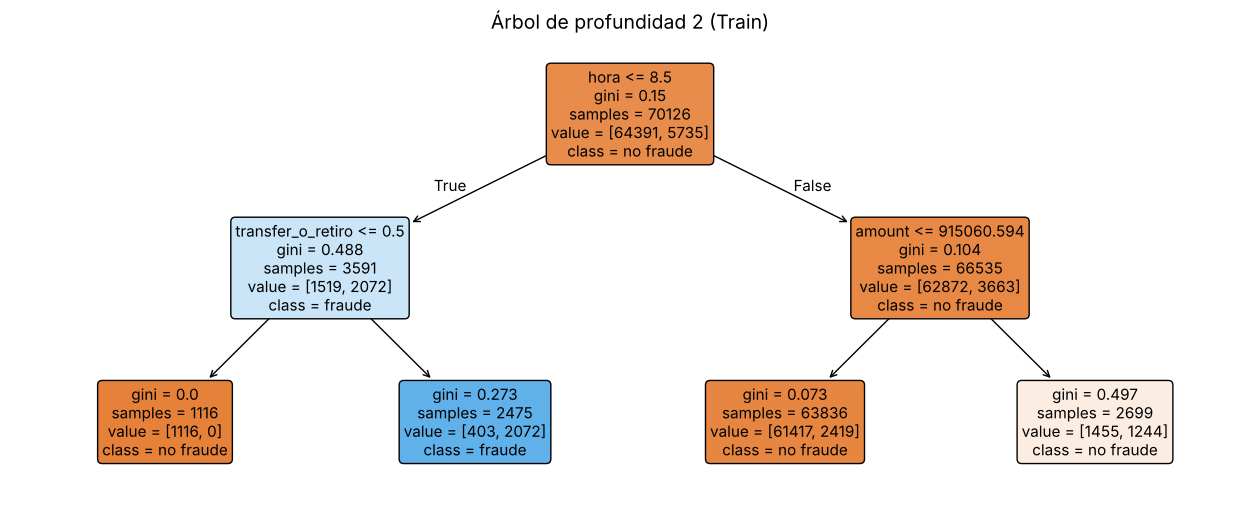

,nodo,pregunta,filas,fraudes,pct_fraude,gini,predice
0,0,hora <= 8.50,70126,5735,8.2,0.150,
1,1,transfer_o_retiro <= 0.50,3591,2072,57.7,0.488,
2,2,hoja,1116,0,0.0,0.000,no fraude
3,3,hoja,2475,2072,83.7,0.273,fraude
4,4,amount <= 915060.59,66535,3663,5.5,0.104,
5,5,hoja,63836,2419,3.8,0.073,no fraude
6,6,hoja,2699,1244,46.1,0.497,no fraude


In [13]:
arbol_pay2 = DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=42)
arbol_pay2.fit(X_train_pay, y_train_pay)

fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(arbol_pay2, feature_names=FEAT_PAY, class_names=["no fraude", "fraude"], filled=True,
          rounded=True, precision=3, fontsize=11, ax=ax)
ax.set_title("Árbol de profundidad 2 (Train)", fontsize=14)
plt.show()

t = arbol_pay2.tree_
filas_nodos = []
for i in range(t.node_count):
    hoja = t.children_left[i] == -1
    frac = t.value[i][0][1] / t.value[i][0].sum()
    filas_nodos.append({"nodo": i,
                        "pregunta": "hoja" if hoja else f"{FEAT_PAY[t.feature[i]]} <= {t.threshold[i]:.2f}",
                        "filas": int(t.n_node_samples[i]), "fraudes": int(round(frac * t.n_node_samples[i])),
                        "pct_fraude": round(100 * frac, 1), "gini": round(t.impurity[i], 3),
                        "predice": ("fraude" if frac > 0.5 else "no fraude") if hoja else ""})
pd.DataFrame(filas_nodos)

**Lee el árbol.** La raíz es Train completo, con 8,2 % de fraude (Gini 0,150). El algoritmo eligió la misma pregunta que ganó en nuestra tabla: **¿hora ≤ 8,5?** En la madrugada pregunta si es transferencia o retiro: si no lo es, la hoja es **pura** (ningún fraude); si lo es, más del 80 % son fraude y la hoja predice `fraude`. Durante el día pregunta por el monto: por encima de unos 915 000 el fraude llega a cerca de 46 %, pero sigue siendo minoría y la hoja predice `no fraude`.

## A.6 El árbol completo y su matriz de confusión

Usamos `max_depth=5` y `min_samples_leaf=30`: los mismos hiperparámetros que estudiamos en el Día 2. **Más hojas no implican mejor modelo:** falta saber cuántas respuestas fueron correctas.

In [14]:
arbol = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42)
arbol.fit(X_train_pay, y_train_pay)
pred_arbol_val = arbol.predict(X_val_pay)
print("Profundidad aprendida:", arbol.get_depth(), "| Hojas:", arbol.get_n_leaves())
print("Alertas de fraude en Validation:", int(pred_arbol_val.sum()), "de", len(pred_arbol_val))

Profundidad aprendida: 5 | Hojas: 21
Alertas de fraude en Validation: 829 de 15063


### Una predicción aislada no revela todos los errores

Supongamos que el árbol marca 800 transacciones como fraude. Ese número no dice si fueron 800 fraudes reales o 800 falsas alarmas. También debemos preguntar cuántos fraudes reales dejó pasar. Para responder cruzamos, **fila por fila**, la clase real con la predicción: el resultado es la **matriz de confusión**. Su nombre significa que deja ver qué clases confundió el modelo.

## ¿Qué es una matriz de confusión?

Es una **tabla de conteos** que enfrenta lo que ocurrió con lo que predijo un clasificador. **Cada transacción de Validation entra exactamente en una de sus cuatro casillas.** Las filas representan la clase real; las columnas, la clase predicha:

| Clase real ↓ / Predicción → | `no fraude` predicho | `fraude` predicho |
| --- | ---: | ---: |
| **`no fraude` real** | **VN:** era normal y dijo normal | **FP:** era normal y dijo fraude (falsa alarma) |
| **`fraude` real** | **FN:** era fraude y dijo normal (fraude que se escapó) | **VP:** era fraude y dijo fraude (fraude detectado) |

### Cómo leer los nombres sin confundirse

Cada nombre tiene dos palabras y cada una responde una pregunta distinta:

- **La segunda palabra (positivo / negativo) dice qué respondió el modelo.** «Positivo» es la clase que decidimos buscar —aquí, **fraude**—; «negativo» es la otra, **normal**. *Positivo no significa bueno.*
- **La primera palabra (verdadero / falso) dice si el modelo acertó.**

Así: **VP** = el modelo dijo *fraude* y **acertó** (era fraude). **VN** = dijo *normal* y acertó (era normal). **FP** = dijo *fraude* y se equivocó (era normal). **FN** = dijo *normal* y se equivocó (era fraude). Si algún día eligiéramos «normal» como clase positiva, los nombres se intercambiarían; por eso **siempre se declara primero cuál es la clase positiva**.

### Ejemplo: 1 000 transacciones

Imaginemos que entrenamos el `DecisionTreeClassifier` y evaluamos 1 000 transacciones que no utilizó para aprender: **980 normales y 20 fraudulentas**. Matriz ilustrativa:

| | Predice normal | Predice fraude |
|---|---:|---:|
| **Real normal** | **950** VN (correctos) | **30** FP (falsas alarmas) |
| **Real fraude** | **5** FN (fraudes omitidos) | **15** VP (fraudes detectados) |

| Resultado | Qué significa en un sistema de pagos |
|---|---|
| Verdadero negativo (950) | La operación era normal y el sistema la clasificó correctamente |
| Falso positivo (30) | La operación era legítima, pero el sistema generó una alerta |
| Falso negativo (5) | Era fraude, pero el modelo no lo detectó |
| Verdadero positivo (15) | Era fraude y el modelo lo detectó |

Para una institución financiera, los **falsos negativos** son fraudes que pueden pasar desapercibidos; los **falsos positivos** consumen recursos de revisión y pueden afectar a usuarios legítimos. Comprueba siempre los totales antes de calcular: filas 980 + 20, columnas 955 predichas normales y 45 alertas, total 1 000. Ahora veamos la matriz **real del árbol en Validation**.

                pred no fraude  pred fraude
real no fraude           13619          161
real fraude                615          668
VN (normal y dijo normal): 13619 | FP (normal y dijo fraude): 161
FN (fraude y dijo normal): 615 | VP (fraude y dijo fraude): 668


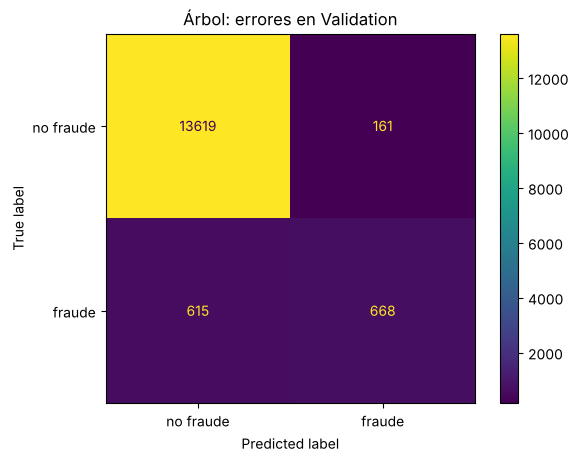

In [15]:
# Orden [0, 1]: filas reales (no fraude, fraude), columnas predichas (no fraude, fraude).
matriz_arbol = confusion_matrix(y_val_pay, pred_arbol_val, labels=[0, 1])
vn, fp, fn, vp = matriz_arbol.ravel()
print(pd.DataFrame(matriz_arbol, index=["real no fraude", "real fraude"], columns=["pred no fraude", "pred fraude"]))
print("VN (normal y dijo normal):", vn, "| FP (normal y dijo fraude):", fp)
print("FN (fraude y dijo normal):", fn, "| VP (fraude y dijo fraude):", vp)
ConfusionMatrixDisplay.from_predictions(y_val_pay, pred_arbol_val, display_labels=["no fraude", "fraude"], values_format="d")
plt.title("Árbol: errores en Validation")
plt.show()

## A.7 Las métricas nuevas, una por una

Hasta ahora medíamos errores con MAE, RMSE o R², porque predecíamos números. En clasificación son **nuevas** cuatro métricas. Todas salen de las cuatro casillas, pero cada una usa un **denominador distinto**, es decir, responde una pregunta distinta. Primero el ejemplo de 1 000 transacciones; después, la matriz real del árbol.

| Métrica | Pregunta que responde | Fórmula | Ejemplo (950 VN, 30 FP, 5 FN, 15 VP) |
| --- | --- | --- | --- |
| **Accuracy** (exactitud) | Porcentaje total de operaciones correctamente clasificadas | $(VP+VN)/\text{total}$ | $(950+15)/1000 = 96{,}5\,\%$ |
| **Precision** (precisión de alertas) | De todas las transacciones señaladas como fraude, ¿cuántas realmente lo eran? | $VP/(VP+FP)$ | $15/45 = 33{,}3\,\%$ |
| **Recall** (sensibilidad) | De todos los fraudes reales, ¿cuántos encontró el modelo? | $VP/(VP+FN)$ | $15/20 = 75{,}0\,\%$ |
| **F1-score** | Combina Precision y Recall con su media armónica | $2VP/(2VP+FP+FN)$ | $30/65 = 46{,}2\,\%$ |

**Cómo recordarlas.** Accuracy mira toda la tabla. Precision mira **la columna** de las alertas («¿mis alarmas son confiables?»). Recall mira **la fila** de los fraudes reales («¿se me escapan?»). F1 es la **media armónica** de las dos.

### ¿Por qué no podemos confiar únicamente en Accuracy?

Nuestro árbol obtuvo 96,5 % de Accuracy, aparentemente excelente. Pero imagina otro modelo que siempre diga «todas las transacciones son normales». Como 980 de las 1 000 son legítimas, ese modelo consigue $980/1000 = 98\,\%$: **más Accuracy que nuestro árbol, aunque no detecta ni un solo fraude**. Por eso en detección de fraude analizamos especialmente Recall y Precision, además del costo de cada tipo de error.

### F1: la métrica para todo problema de clasificación con una clase rara

F1 es un solo número entre 0 y 1 que solo es alto si Precision **y** Recall lo son. Su fórmula $2VP/(2VP+FP+FN)$ **no usa los verdaderos negativos**: los cientos de normales bien aceptadas no la inflan, como sí inflan la Accuracy. El modelo «siempre normal» tiene Accuracy 98 % pero F1 = 0. Por eso F1 será nuestra métrica principal en todo el notebook —fraude, abandono e impago— para elegir hiperparámetros y comparar árbol, bosque, KNN y SVM en Validation.

In [16]:
# Ejemplo de 1 000 transacciones: métricas a mano
VP, VN, FP, FN = 15, 950, 30, 5
accuracy_demo = (VP + VN) / (VP + VN + FP + FN)
precision_demo = VP / (VP + FP)
recall_demo = VP / (VP + FN)
f1_demo = 2 * precision_demo * recall_demo / (precision_demo + recall_demo)
print({"Accuracy": round(accuracy_demo, 3), "Precision": round(precision_demo, 3),
       "Recall": round(recall_demo, 3), "F1": round(f1_demo, 3)})
print("F1 con conteos, 2VP/(2VP+FP+FN):", round(2 * VP / (2 * VP + FP + FN), 3))
print("Modelo «siempre normal»: Accuracy", (VN + FP) / (VP + VN + FP + FN), "| fraudes detectados: 0 | F1: 0")

{'Accuracy': 0.965, 'Precision': 0.333, 'Recall': 0.75, 'F1': 0.462}
F1 con conteos, 2VP/(2VP+FP+FN): 0.462
Modelo «siempre normal»: Accuracy 0.98 | fraudes detectados: 0 | F1: 0


### Ahora con la matriz real del árbol

La celda siguiente calcula las cuatro métricas **a mano** con los conteos de la matriz del árbol y las compara con las funciones de scikit-learn. Deben coincidir.

In [17]:
acc_mano = (vp + vn) / (vp + vn + fp + fn)
prec_mano = vp / (vp + fp)
rec_mano = vp / (vp + fn)
f1_mano = 2 * prec_mano * rec_mano / (prec_mano + rec_mano)
print(f"Accuracy  = ({vp} + {vn}) / {vp + vn + fp + fn} = {acc_mano:.3f}   | sklearn: {accuracy_score(y_val_pay, pred_arbol_val):.3f}")
print(f"Precision = {vp} / ({vp} + {fp}) = {prec_mano:.3f}   | sklearn: {precision_score(y_val_pay, pred_arbol_val):.3f}")
print(f"Recall    = {vp} / ({vp} + {fn}) = {rec_mano:.3f}   | sklearn: {recall_score(y_val_pay, pred_arbol_val):.3f}")
print(f"F1        = 2·{prec_mano:.3f}·{rec_mano:.3f} / ({prec_mano:.3f} + {rec_mano:.3f}) = {f1_mano:.3f}   | sklearn: {f1_score(y_val_pay, pred_arbol_val):.3f}")

Accuracy  = (668 + 13619) / 15063 = 0.948   | sklearn: 0.948
Precision = 668 / (668 + 161) = 0.806   | sklearn: 0.806
Recall    = 668 / (668 + 615) = 0.521   | sklearn: 0.521
F1        = 2·0.806·0.521 / (0.806 + 0.521) = 0.633   | sklearn: 0.633


### Medir referencias y árbol de la misma forma

La función `resumen` que definimos al inicio convierte esas cuatro preguntas en columnas. `zero_division=0` evita un error cuando un modelo no emite **ninguna** alerta: el cero de Precision es una convención de reporte.

In [18]:
resultados_pay = [resumen(y_val_pay, pred_base_pay, "Baseline (siempre no fraude)"),
                  resumen(y_val_pay, pred_regla_pay, "Regla isFlaggedFraud"),
                  resumen(y_val_pay, pred_arbol_val, "Árbol")]
print(pd.DataFrame(resultados_pay).set_index("modelo").round(3))
pd.DataFrame([conteos(y_val_pay, pred_base_pay, "Baseline (siempre no fraude)"),
              conteos(y_val_pay, pred_regla_pay, "Regla isFlaggedFraud"),
              conteos(y_val_pay, pred_arbol_val, "Árbol")]).set_index("modelo")

                              accuracy  precision_pos  recall_pos  f1_pos
modelo                                                                   
Baseline (siempre no fraude)     0.915          0.000       0.000   0.000
Regla isFlaggedFraud             0.915          1.000       0.004   0.008
Árbol                            0.948          0.806       0.521   0.633


,VN,FP,FN,VP,alertas
modelo,,,,,
Baseline (siempre no fraude),13780,0,1283,0,0
Regla isFlaggedFraud,13780,0,1278,5,5
Árbol,13619,161,615,668,829


**Lee la tabla.** Las tres opciones tienen Accuracy entre 0,91 y 0,95: con ese número **no se distinguen**. La diferencia está en las otras columnas. La regla del negocio tiene **Precision 1,00** (todas sus alertas eran fraude) pero un **Recall casi nulo**. El árbol detecta cerca de la mitad de los fraudes y, cuando avisa, acierta en unos 8 de cada 10 casos.

### ¿Por qué F1 y no el promedio simple?

La regla del negocio tiene Precision 1,00 y Recall cercano a 0,004. Su **promedio simple** sería cerca de 0,50, como si fuera un modelo «regular». Pero una regla que no encuentra casi ningún fraude **no sirve**. F1 usa la media armónica, que se acerca al valor más bajo: para la regla da cerca de 0,008. **F1 solo es alto cuando Precision y Recall son altas a la vez.**

In [19]:
p_regla = precision_score(y_val_pay, pred_regla_pay, zero_division=0)
r_regla = recall_score(y_val_pay, pred_regla_pay)
print(f"Regla — Precision {p_regla:.3f}, Recall {r_regla:.4f}")
print(f"Promedio simple: {(p_regla + r_regla) / 2:.3f}   |   F1 (media armónica): {f1_score(y_val_pay, pred_regla_pay):.4f}")

Regla — Precision 1.000, Recall 0.0039
Promedio simple: 0.502   |   F1 (media armónica): 0.0078


### ¿Qué métrica elegir?

No hay una métrica «correcta» para todo: depende de **qué error cuesta más**.

| Situación | Error más costoso | Métrica que conviene mirar |
|---|---|---|
| Fraude, enfermedad grave, impago de un crédito grande | Dejar pasar un positivo (FN) | **Recall** |
| Alertas que requieren mucho trabajo manual; bloquear tarjetas de buenos clientes; filtro de spam | Falsa alarma (FP) | **Precision** |
| Los dos errores importan parecido | Ambos | **F1** |
| Clases equilibradas (≈ 50 / 50) y errores de costo parecido | Ambos | **Accuracy** puede bastar |

En este notebook usaremos F1 como regla didáctica para elegir modelos, pero en un banco real habría que traducir FP y FN a costos.

## A.8 Probar estrategias de balanceo

En A.2 vimos qué es un dataset desbalanceado y seis formas de trabajar con él. Ahora las probamos. Recuerda la regla de oro: **solo se balancea Train**.

Comparemos cuatro estrategias con el mismo árbol (profundidad 5, al menos 30 filas por hoja), evaluadas sobre **la misma Validation sin tocar**.

In [20]:
from sklearn.utils import resample

entreno = X_train_pay.assign(isFraud=y_train_pay)
mayoritaria = entreno[entreno["isFraud"] == 0]
minoritaria = entreno[entreno["isFraud"] == 1]
sobre = pd.concat([mayoritaria, resample(minoritaria, replace=True, n_samples=len(mayoritaria), random_state=42)])
sub = pd.concat([resample(mayoritaria, replace=False, n_samples=len(minoritaria), random_state=42), minoritaria])
print("Train original:", len(entreno), "filas,", round(entreno['isFraud'].mean() * 100, 1), "% fraude")
print("Sobremuestreo:", len(sobre), "filas,", round(sobre['isFraud'].mean() * 100, 1), "% fraude")
print("Submuestreo:", len(sub), "filas,", round(sub['isFraud'].mean() * 100, 1), "% fraude")

arbol_bal = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight="balanced", random_state=42)
arbol_bal.fit(X_train_pay, y_train_pay)
arbol_sobre = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42).fit(sobre[FEAT_PAY], sobre["isFraud"])
arbol_sub = DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42).fit(sub[FEAT_PAY], sub["isFraud"])
pred_arbol_bal_val = arbol_bal.predict(X_val_pay)

estrategias = [("Sin balancear", pred_arbol_val), ("class_weight balanced", pred_arbol_bal_val),
               ("Sobremuestreo en Train", arbol_sobre.predict(X_val_pay)), ("Submuestreo en Train", arbol_sub.predict(X_val_pay))]
print(pd.DataFrame([resumen(y_val_pay, p, n) for n, p in estrategias]).set_index("modelo").round(3))
pd.DataFrame([conteos(y_val_pay, p, n) for n, p in estrategias]).set_index("modelo")

Train original: 70126 filas, 8.2 % fraude
Sobremuestreo: 128782 filas, 50.0 % fraude
Submuestreo: 11470 filas, 50.0 % fraude


                        accuracy  precision_pos  recall_pos  f1_pos
modelo                                                             
Sin balancear              0.948          0.806       0.521   0.633
class_weight balanced      0.854          0.347       0.808   0.486
Sobremuestreo en Train     0.833          0.317       0.829   0.459
Submuestreo en Train       0.893          0.427       0.748   0.544


,VN,FP,FN,VP,alertas
modelo,,,,,
Sin balancear,13619,161,615,668,829
class_weight balanced,11829,1951,246,1037,2988
Sobremuestreo en Train,11492,2288,220,1063,3351
Submuestreo en Train,12493,1287,323,960,2247


**Interpretación.** Las tres estrategias de balanceo hacen lo mismo en el fondo: le dicen al árbol que los fraudes importan más. Con cualquiera de ellas el Recall sube mucho (de cerca de 0,5 a 0,75 – 0,83): se escapan muchos menos fraudes. El precio es que la Precision cae a 0,32 – 0,43, porque aparecen muchas más falsas alarmas, y el F1 baja. **Balancear no es «mejorar» sin más: es mover el intercambio hacia el Recall.** Conviene cuando un fraude perdido cuesta mucho más que revisar una alerta.

## A.9 Random Forest y un árbol que memoriza

Un árbol puede cambiar sus preguntas si cambian algunas filas de Train. **Random Forest** construye muchos árboles, cada uno con una **muestra bootstrap** de Train (filas sorteadas con reemplazo) y con un subconjunto aleatorio de columnas en cada corte. Cada árbol **vota** por una clase y el bosque decide por mayoría: es la misma idea del Día 2, pero en lugar de promediar números se cuentan votos.

`n_estimators=200` indica cuántos árboles se entrenan; `max_depth=8` y `min_samples_leaf=5` limitan cada árbol. También entrenamos un árbol **sin ningún límite** para ver qué pasa cuando se le permite memorizar.

In [21]:
bosque = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1)
bosque_bal = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, class_weight="balanced",
                                    random_state=42, n_jobs=-1)
arbol_libre = DecisionTreeClassifier(random_state=42)
for modelo in [bosque, bosque_bal, arbol_libre]:
    modelo.fit(X_train_pay, y_train_pay)

candidatos_pay = {"Árbol": arbol, "Árbol balanced": arbol_bal, "Random Forest": bosque,
                  "Random Forest balanced": bosque_bal, "Árbol sin límite": arbol_libre}
filas = []
for nombre, modelo in candidatos_pay.items():
    fila = resumen(y_val_pay, modelo.predict(X_val_pay), nombre)
    fila["f1_train"] = f1_score(y_train_pay, modelo.predict(X_train_pay))
    fila["brecha_f1"] = fila["f1_train"] - fila["f1_pos"]
    filas.append(fila)
tabla_pay = pd.DataFrame(filas).set_index("modelo")
print("Hojas del árbol sin límite:", arbol_libre.get_n_leaves())
tabla_pay.round(3)

Hojas del árbol sin límite: 3413


,accuracy,precision_pos,recall_pos,f1_pos,f1_train,brecha_f1
modelo,,,,,,
Árbol,0.948,0.806,0.521,0.633,0.610,-0.023
Árbol balanced,0.854,0.347,0.808,0.486,0.474,-0.011
Random Forest,0.949,0.823,0.506,0.626,0.620,-0.006
Random Forest balanced,0.849,0.339,0.814,0.479,0.483,0.004
Árbol sin límite,0.931,0.626,0.465,0.534,0.998,0.464


### Leer la comparación

1. **El árbol sin límite memoriza.** En Train obtiene F1 cercano a 1 con miles de hojas, pero en Validation cae muy por debajo del árbol de profundidad 5: aprendió los montos exactos de Train, que no se repiten en Validation. Es el sobreajuste del Día 2. **Nota:** si hubiéramos dividido al azar, sin agrupar las dos patas de cada fraude, este árbol habría parecido el mejor; separar por operación evita ese espejismo.
2. **El árbol controlado no memoriza:** su F1 de Train y de Validation son casi iguales (brecha cercana a 0).
3. **El bosque** obtiene casi el mismo F1 que el árbol de profundidad 5. Si no mejora la métrica que importa, su mayor costo de cálculo y su menor facilidad para explicarse no se justifican.
4. **Las versiones balanceadas** suben el Recall a cambio de Precision, como vimos en A.8.

In [22]:
# ¿Qué variable usó más el bosque para reducir el Gini?
importancia_pay = pd.Series(bosque.feature_importances_, index=FEAT_PAY).sort_values(ascending=False)
print(importancia_pay.round(3))

hora                 0.445
amount               0.380
transfer_o_retiro    0.175
dtype: float64


**Interpretación.** La importancia suma cuánto redujo el Gini cada variable en todos los cortes de los 200 árboles. Es importancia **predictiva**: no dice que la hora cause el fraude ni en qué dirección actúa cada variable, y en un dataset sintético refleja cómo se programó la simulación.

# Parte B · BankChurners: KNN, clasificar por parecido

## B.1 El problema y el dataset

**El problema.** Un gerente de un banco está preocupado porque cada vez más clientes abandonan su servicio de tarjeta de crédito. Le sería muy útil predecir qué clientes se van a ir, para acercarse a ellos de forma proactiva, ofrecerles un mejor servicio y hacer que cambien su decisión.

**El dataset.** Se publicó en Kaggle a partir del sitio LEAPS de Analyttica (<https://leaps.analyttica.com/home>), que propone problemas de negocio y explica cómo resolverlos. Contiene **10 127 clientes** con datos como edad, ingreso, estado civil, límite de crédito y categoría de tarjeta: cerca de 18 variables. Solo el **16,07 %** abandonó la tarjeta; por eso es más difícil entrenar un modelo que detecte a quienes se van. Ya lo usamos en el Día 2 para estimar el monto transado; hoy la respuesta es `Attrition_Flag`.

**Por qué lo usamos para KNN.** Contiene **comportamiento transaccional, límite de crédito y actividad del cliente**. Es adecuado para explicar cómo KNN clasifica a un cliente nuevo basándose en **clientes similares**: si los clientes que más se le parecen se fueron, es una señal de alerta.

In [23]:
churn = pd.read_csv(ARCHIVO_CHURN)
print("Dimensiones:", churn.shape)
print(churn["Attrition_Flag"].value_counts())
y_ch = (churn["Attrition_Flag"] == "Attrited Customer").astype(int)   # 1 = abandonó
print("Proporción de abandono:", round(y_ch.mean() * 100, 2), "%")

# Dos columnas son predicciones de un modelo Naive Bayes que ya conocía la respuesta.
cols_fuga = [c for c in churn.columns if c.startswith("Naive_Bayes")]
regla_fuga = (churn[cols_fuga[0]] > 0.5).astype(int)
print("Accuracy de la regla «columna Naive_Bayes > 0,5»:", accuracy_score(y_ch, regla_fuga))

Dimensiones: (10127, 23)
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64
Proporción de abandono: 16.07 %
Accuracy de la regla «columna Naive_Bayes > 0,5»: 1.0


**Una fuga evidente.** Las dos últimas columnas del archivo se llaman `Naive_Bayes_Classifier_…`: son el resultado de un modelo que alguien entrenó **usando la respuesta**. Una regla tan simple como «si esa columna supera 0,5, predice abandono» acierta el **100 %** de los clientes. Si la dejáramos, cualquier algoritmo parecería perfecto y no aprenderíamos nada útil. La eliminamos, junto con `CLIENTNUM`, que solo es un número de identificación.

Para KNN usaremos **11 variables numéricas de comportamiento**, porque la distancia entre clientes se entiende mejor con números:

| Columna | Significado |
|---|---|
| `Customer_Age` | Edad |
| `Credit_Limit` | Límite de crédito (USD) |
| `Total_Revolving_Bal` | Saldo que el cliente arrastra de un mes a otro (USD) |
| `Total_Trans_Amt` / `Total_Trans_Ct` | Monto y número de transacciones en 12 meses |
| `Total_Amt_Chng_Q4_Q1` / `Total_Ct_Chng_Q4_Q1` | Cambio del monto y del número de transacciones: cuarto trimestre frente al primero |
| `Avg_Utilization_Ratio` | Proporción del límite que usa en promedio |
| `Months_Inactive_12_mon` | Meses sin actividad en el último año |
| `Contacts_Count_12_mon` | Veces que contactó al banco en el último año |
| `Total_Relationship_Count` | Número de productos que tiene con el banco |

In [24]:
X_ch = churn.drop(columns=["CLIENTNUM", "Attrition_Flag", *cols_fuga])
FEAT_KNN = ["Customer_Age", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Total_Trans_Ct",
            "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1", "Avg_Utilization_Ratio",
            "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Total_Relationship_Count"]
X_train_ch, X_rest_ch, y_train_ch, y_rest_ch = train_test_split(
    X_ch, y_ch, test_size=0.30, random_state=42, stratify=y_ch)
X_val_ch, X_test_ch, y_val_ch, y_test_ch = train_test_split(
    X_rest_ch, y_rest_ch, test_size=0.50, random_state=42, stratify=y_rest_ch)
print("Train / Validation / Test:", X_train_ch.shape, X_val_ch.shape, X_test_ch.shape)
print("Abandonos en Validation:", int(y_val_ch.sum()), "de", len(y_val_ch))

baseline_ch = DummyClassifier(strategy="most_frequent").fit(X_train_ch, y_train_ch)
resultados_ch = [resumen(y_val_ch, baseline_ch.predict(X_val_ch), "Baseline")]
pd.DataFrame(resultados_ch).set_index("modelo").round(3)

Train / Validation / Test: (7088, 19) (1519, 19) (1520, 19)
Abandonos en Validation: 244 de 1519


,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
Baseline,0.839,0.0,0.0,0.0


## KNN: ¿qué significa su nombre y qué hace?

**KNN** son las siglas inglesas de *K-Nearest Neighbors*, es decir, **los k vecinos más cercanos**. La letra **k** representa cuántos clientes conocidos consultamos; *nearest* significa «más próximos» y *neighbors*, «vecinos». Por ejemplo, con `k=15`, para un cliente nuevo buscamos quince clientes de **Train** que se le parecen según una distancia matemática. Sus respuestas históricas (se fue / se quedó) ayudan a decidir la clase de la fila nueva. En el ejemplo manual de abajo todos tienen un voto; en el modelo real `weights="distance"` dará más peso a quienes estén más cerca.

¿Para qué serviría aquí? Si un cliente actual se comporta como clientes de Train que abandonaron la tarjeta, KNN lo marca como posible abandono; si se parece más a quienes se quedaron, responde «se queda». La palabra «parecido» depende **de las columnas, las escalas y la distancia elegida**: no significa que el algoritmo conozca los gustos o las intenciones del cliente. KNN no formula preguntas como un árbol; compara la fila nueva con ejemplos guardados.

Un `k` pequeño puede depender demasiado de unos pocos clientes atípicos. Un `k` grande suaviza la decisión, pero la mayoría que se queda puede dominar. KNN recibe números escalados dentro del Pipeline para que una unidad grande no decida por sí sola quién es vecino.

<p align="center">
    <img src="../material_apoyo/knn.png" width="550">
</p>

### ¿Cómo se decide quién es «cercano»?

En un dibujo con dos variables podemos señalar los vecinos de una persona nueva. El ejemplo de código siguiente usa cuatro puntos inventados: calcula distancias, escoge los tres más cercanos y cuenta sus etiquetas. Una **distancia** resume en un número cuánto difieren las características de dos filas; cuanto menor sea, más cercanas son bajo esa regla.

Elegimos primero la **distancia euclidiana**, la distancia en línea recta: si dos puntos difieren 3 unidades en una coordenada y 4 en otra, su distancia es $\sqrt{3^2+4^2}=5$. Otra posibilidad es la **distancia Manhattan**, que suma desplazamientos por cada coordenada, como caminar por calles en cuadrícula: $|3|+|4|=7$. **No hay una ganadora universal.** Para KNN, euclidiana es la opción predeterminada (`p=2` de Minkowski); Manhattan corresponde a `p=1`. Después las compararemos sobre los **mismos clientes de Validation**.

<p align="center">
    <img src="../material_apoyo/distance.png" width="450">
</p>

Antes de medir distancias reales escalamos las columnas numéricas. Por ello «más cercano» significa cercano **según esta representación**, no necesariamente similar en un sentido económico o personal.

In [25]:
# Votación KNN manual en un ejemplo de dos dimensiones
consulta = np.array([2.0, 2.0])
X_juguete = np.array([[1.0, 1.0], [2.5, 2.0], [4.0, 3.0], [1.5, 3.0]])
clases_juguete = np.array([0, 1, 1, 0])
distancias = np.linalg.norm(X_juguete - consulta, axis=1)
orden = np.argsort(distancias)
print("distancias:", np.round(distancias, 2))
print("orden de vecinos:", orden)
print("clases de los 3 vecinos:", clases_juguete[orden[:3]])
print("clase por voto mayoritario:", int(np.bincount(clases_juguete[orden[:3]]).argmax()))

distancias: [1.41 0.5  2.24 1.12]
orden de vecinos: [1 3 0 2]
clases de los 3 vecinos: [1 0 0]
clase por voto mayoritario: 0


## B.2 Un cliente real y sus 15 vecinos

Ahora con datos reales y solo dos variables, para poder dibujarlo: **número** y **monto** de transacciones en 12 meses. Primero las estandarizamos con la media y la desviación de Train: $z=(x-\bar x)/s$. Así una transacción más y un dólar más no pesan igual por sus unidades. Elegimos un cliente de Validation y buscamos sus 15 clientes más cercanos en Train.

In [26]:
DOS = ["Total_Trans_Ct", "Total_Trans_Amt"]
escalador_2 = StandardScaler().fit(X_train_ch[DOS])
print("Medias de Train:", escalador_2.mean_.round(1), " Desviaciones:", escalador_2.scale_.round(1))
Z_train = escalador_2.transform(X_train_ch[DOS])

POS = 80                                      # un cliente de Validation (no es Test)
cliente = X_val_ch[DOS].iloc[[POS]]
z_cliente = escalador_2.transform(cliente)
print("Cliente nuevo:", cliente.iloc[0].to_dict(), "→ z =", z_cliente.round(2))

dist = np.sqrt(((Z_train - z_cliente) ** 2).sum(axis=1))   # distancia euclidiana
idx15 = np.argsort(dist)[:15]
vecinos = X_train_ch[DOS].iloc[idx15].copy()
vecinos["distancia"] = dist[idx15].round(3)
vecinos["abandonó"] = y_train_ch.iloc[idx15].values
print("Votos de los 15 vecinos — abandonó:", int(vecinos["abandonó"].sum()), " se quedó:", int(15 - vecinos["abandonó"].sum()))
print("¿Qué pasó realmente con este cliente?", "abandonó" if y_val_ch.iloc[POS] == 1 else "se quedó")
vecinos

Medias de Train: [  64.9 4397. ]  Desviaciones: [  23.6 3391.7]
Cliente nuevo: {'Total_Trans_Ct': 48, 'Total_Trans_Amt': 3109} → z = [[-0.71 -0.38]]
Votos de los 15 vecinos — abandonó: 12  se quedó: 3
¿Qué pasó realmente con este cliente? abandonó


,Total_Trans_Ct,Total_Trans_Amt,distancia,abandonó
6971,49,3073,0.044,0
3148,49,3029,0.048,1
640,47,3231,0.056,1
4325,47,3289,0.068,1
9063,47,3315,0.074,1
8357,49,2877,0.080,1
4983,48,2832,0.082,1
8268,49,2870,0.082,1
6871,47,2866,0.083,1
7741,47,3357,0.084,0


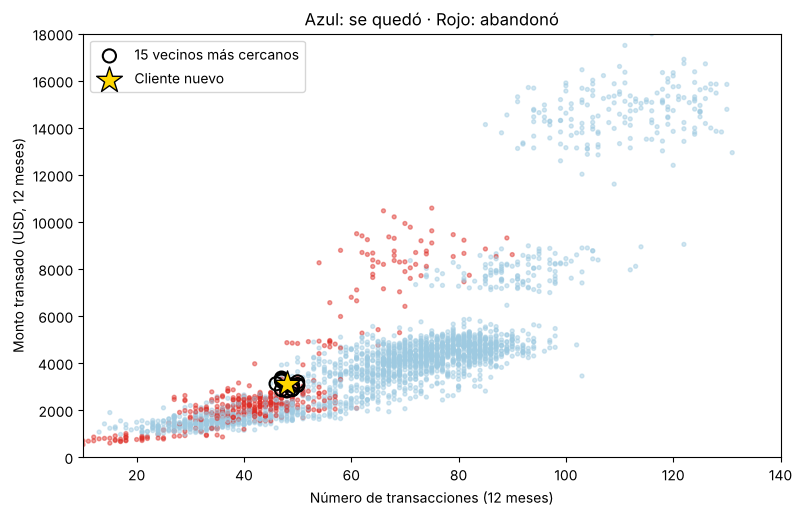

In [27]:
fig, ax = plt.subplots(figsize=(9, 5.5))
fondo = X_train_ch.sample(2500, random_state=1)
ax.scatter(fondo["Total_Trans_Ct"], fondo["Total_Trans_Amt"], c=y_train_ch.loc[fondo.index].map({0: "#9ecae1", 1: "#de2d26"}),
           s=8, alpha=0.45)
ax.scatter(vecinos["Total_Trans_Ct"], vecinos["Total_Trans_Amt"], facecolors="none", edgecolors="black", s=90, lw=1.5,
           label="15 vecinos más cercanos")
ax.scatter(cliente["Total_Trans_Ct"], cliente["Total_Trans_Amt"], marker="*", s=380, color="gold", edgecolor="black",
           zorder=5, label="Cliente nuevo")
ax.set_xlabel("Número de transacciones (12 meses)"); ax.set_ylabel("Monto transado (USD, 12 meses)")
ax.set_title("Azul: se quedó · Rojo: abandonó"); ax.set_xlim(10, 140); ax.set_ylim(0, 18000); ax.legend()
plt.show()

**Lee el resultado.** El cliente hizo 48 transacciones por 3 109 dólares. Entre sus 15 vecinos, **12 abandonaron** la tarjeta: por mayoría, KNN lo marca como posible abandono, y en efecto se fue. En el gráfico se ve por qué: en la zona de pocas transacciones y montos bajos los puntos rojos son frecuentes; a partir de unas 85 transacciones casi no hay abandonos. KNN no aprendió una regla: **consultó a los clientes parecidos** cada vez que recibió uno nuevo.

## B.3 Las escalas: por qué impiden un buen modelo y cómo se normaliza

KNN decide con **distancias**, y una distancia suma diferencias de todas las columnas. Si una columna se mide en miles (monto en dólares) y otra en decenas (número de transacciones), la primera manda: una diferencia de 36 dólares pesa 36 veces más que una transacción de diferencia, aunque en la práctica 36 dólares en un año no signifiquen nada y una transacción tampoco. El modelo termina buscando vecinos **solo por el monto** y se equivoca de vecinos.

Veámoslo con números: comparemos al cliente de B.2 con dos clientes de Train.

In [28]:
cliente_v = cliente.iloc[0]
vecino_a = X_train_ch[DOS].loc[6971]                      # 49 transacciones, 3 073 USD: casi idéntico
vecino_b = X_train_ch[DOS].iloc[((X_train_ch["Total_Trans_Amt"] - 3109).abs() + 1000 * (X_train_ch["Total_Trans_Ct"] < 70)).argmin()]
for nombre, otro in [("Cliente A", vecino_a), ("Cliente B", vecino_b)]:
    d_sin = np.sqrt(((cliente_v - otro) ** 2).sum())
    d_con = np.sqrt((((cliente_v - otro) / escalador_2.scale_) ** 2).sum())
    print(f"{nombre}: {int(otro['Total_Trans_Ct'])} transacciones, {int(otro['Total_Trans_Amt'])} USD | "
          f"distancia sin escalar = {d_sin:.1f} | distancia estandarizada = {d_con:.3f}")

Cliente A: 49 transacciones, 3073 USD | distancia sin escalar = 36.0 | distancia estandarizada = 0.044
Cliente B: 79 transacciones, 3112 USD | distancia sin escalar = 31.1 | distancia estandarizada = 1.312


**Lee el resultado.** El cliente B hizo muchas más transacciones (un comportamiento muy distinto), pero como su monto es casi igual, **sin escalar parece más cercano** que el cliente A, que es casi idéntico. Con las variables estandarizadas el orden se corrige: A queda muy cerca y B lejos. Por eso, en KNN (y en SVM) **normalizar no es opcional**.

### Dos formas de normalizar

| Método | Fórmula | Resultado | En scikit-learn |
|---|---|---|---|
| **Estandarización** (puntaje z) | $z = (x - \bar x)/s$ | Media 0 y desviación 1: «¿cuántas desviaciones está por encima o por debajo del promedio?» | `StandardScaler` |
| **Min-max** | $x' = (x - \min)/(\max - \min)$ | Valores entre 0 y 1: «¿en qué punto del rango está?» | `MinMaxScaler` |

Ejemplo con el cliente (48 transacciones, 3 109 USD). Estandarización: $(48-64{,}9)/23{,}6 = -0{,}71$ y $(3\,109-4\,397)/3\,391{,}7 = -0{,}38$. Min-max usa el mínimo y el máximo de Train (la celda siguiente los calcula). La estandarización es la opción habitual; min-max es sensible a valores extremos, porque un solo cliente con un monto enorme estira todo el rango.

**Regla:** la media, la desviación, el mínimo y el máximo se aprenden **solo con Train** (dentro del `Pipeline`) y se aplican igual a Validation y Test.

In [29]:
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler().fit(X_train_ch[DOS])
print("Mínimos de Train:", mm.data_min_, "| Máximos de Train:", mm.data_max_)
print("Cliente estandarizado:", escalador_2.transform(cliente).round(2), "| Cliente min-max:", mm.transform(cliente).round(3))

# ¿Cambian los 15 vecinos si no escalamos?
dist_sin = np.sqrt(((X_train_ch[DOS].to_numpy() - cliente.to_numpy()) ** 2).sum(axis=1))
idx15_sin = np.argsort(dist_sin)[:15]
print("Vecinos en común entre «sin escalar» y «estandarizado»:", len(set(idx15_sin) & set(idx15)), "de 15")
print("Abandonos entre los 15 vecinos sin escalar:", int(y_train_ch.iloc[idx15_sin].sum()),
      "| rango de transacciones de esos vecinos:", int(X_train_ch[DOS].iloc[idx15_sin]["Total_Trans_Ct"].min()), "a",
      int(X_train_ch[DOS].iloc[idx15_sin]["Total_Trans_Ct"].max()))

Mínimos de Train: [ 10. 530.] | Máximos de Train: [  139. 17995.]
Cliente estandarizado: [[-0.71 -0.38]] | Cliente min-max: [[0.295 0.148]]
Vecinos en común entre «sin escalar» y «estandarizado»: 2 de 15
Abandonos entre los 15 vecinos sin escalar: 2 | rango de transacciones de esos vecinos: 45 a 73


**Lee el resultado.** Sin escalar, de los 15 vecinos solo 2 coinciden con los vecinos estandarizados, y entre ellos solo 2 abandonaron (frente a 12): KNN diría que el cliente se queda y **se equivocaría**. Son vecinos con 45 a 73 transacciones, elegidos casi solo porque su monto se parece.

Ahora comparemos el mismo KNN (`k=15`) **sin escalar, estandarizado y con min-max**, con dos variables y con las 11 variables de comportamiento.

In [30]:
filas_escala = []
for columnas, etiqueta in [(DOS, "2 variables"), (FEAT_KNN, "11 variables")]:
    for nombre_esc, pasos in [("sin escalar", []), ("estandarizado", [("scale", StandardScaler())]), ("min-max", [("scale", MinMaxScaler())])]:
        modelo = Pipeline(pasos + [("model", KNeighborsClassifier(n_neighbors=15))]).fit(X_train_ch[columnas], y_train_ch)
        filas_escala.append(resumen(y_val_ch, modelo.predict(X_val_ch[columnas]), f"KNN k=15 · {etiqueta} · {nombre_esc}"))
resultados_ch += filas_escala[:2]
pd.DataFrame(filas_escala).set_index("modelo").round(3)

,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
KNN k=15 · 2 variables · sin escalar,0.890,0.736,0.492,0.590
KNN k=15 · 2 variables · estandarizado,0.907,0.754,0.627,0.685
KNN k=15 · 2 variables · min-max,0.907,0.752,0.623,0.682
KNN k=15 · 11 variables · sin escalar,0.892,0.708,0.557,0.624
KNN k=15 · 11 variables · estandarizado,0.914,0.831,0.586,0.688
KNN k=15 · 11 variables · min-max,0.911,0.819,0.574,0.675


**Interpretación.** Con dos variables, normalizar sube el F1 de cerca de 0,59 a 0,69; con las 11 variables, de cerca de 0,62 a 0,69. Sin escalar, el límite de crédito y los montos (miles de dólares) aplastan a variables como meses inactivo o número de productos (unidades). Estandarizar o usar min-max devuelve a cada variable un peso comparable; aquí los dos métodos dan resultados muy parecidos. **En KNN la escala es parte del modelo.**

### Elegir `k`, la forma de votar y la distancia

`k` indica cuántos vecinos participan. Con `k=1`, un único cliente puede determinar la respuesta; con valores mayores, entran más casos, pero los muchos clientes que se quedan pueden acabar dominando. En el dibujo manual cada vecino tenía un voto igual. En el experimento real `weights="distance"` da más peso a vecinos cercanos: alguien casi idéntico influye más que otro al borde de los quince elegidos.

En el primer experimento probamos `k=5`, `15` y `31` manteniendo la distancia euclidiana. Después, **sin cambiar `k=15`, los pesos, Train ni Validation**, probaremos Manhattan. Así distinguimos el efecto de elegir más vecinos del efecto de medir cercanía de otra manera. La regla que se prefiera debe responder a los errores que importan —encontrar abandonos sin producir demasiados avisos falsos— y se elige en Validation, nunca mirando Test.

In [31]:
# Las 11 variables numéricas, escaladas dentro del Pipeline (media y desviación de Train).
modelos_knn = {}
for k in [5, 15, 31]:
    modelo = Pipeline([("scale", StandardScaler()),
                       ("model", KNeighborsClassifier(n_neighbors=k, weights="distance"))])
    modelo.fit(X_train_ch[FEAT_KNN], y_train_ch)
    modelos_knn[f"KNN k={k}"] = modelo
modelo = Pipeline([("scale", StandardScaler()),
                   ("model", KNeighborsClassifier(n_neighbors=15, weights="distance", metric="manhattan"))])
modelos_knn["KNN k=15 Manhattan"] = modelo.fit(X_train_ch[FEAT_KNN], y_train_ch)

tabla_knn = pd.DataFrame([resumen(y_val_ch, m.predict(X_val_ch[FEAT_KNN]), n) for n, m in modelos_knn.items()]).set_index("modelo")
print(tabla_knn.round(3))
pd.DataFrame([conteos(y_val_ch, m.predict(X_val_ch[FEAT_KNN]), n) for n, m in modelos_knn.items()]).set_index("modelo")

                    accuracy  precision_pos  recall_pos  f1_pos
modelo                                                         
KNN k=5                0.918          0.823       0.627   0.712
KNN k=15               0.914          0.831       0.586   0.688
KNN k=31               0.908          0.833       0.533   0.650
KNN k=15 Manhattan     0.922          0.849       0.623   0.719


,VN,FP,FN,VP,alertas
modelo,,,,,
KNN k=5,1242,33,91,153,186
KNN k=15,1246,29,101,143,172
KNN k=31,1249,26,114,130,156
KNN k=15 Manhattan,1248,27,92,152,179


### ¿Qué indican los resultados de KNN?

Compara primero con el baseline, que no detectaba ningún abandono. Con 11 variables escaladas, KNN encuentra más de la mitad de los 244 abandonos de Validation y, cuando avisa, acierta en más de 8 de cada 10 casos. Mira cómo cambian FP y FN al mover `k`: con pocos vecinos la decisión depende de pocos clientes; con muchos, la mayoría que se queda pesa más. La distancia Manhattan cambia quiénes son los vecinos y, con ello, algunos avisos. Una diferencia pequeña en esta Validation puede deberse a los clientes concretos que cayeron en ella.

## B.4 ¿Más columnas siempre ayudan a KNN?

Probemos un KNN con **todas** las columnas: las 11 numéricas, las demás numéricas y las categorías (sexo, educación, estado civil, ingreso, tipo de tarjeta) convertidas con One-Hot.

In [32]:
num_ch = X_ch.select_dtypes(include="number").columns.tolist()
cat_ch = X_ch.select_dtypes(exclude="number").columns.tolist()
pre_ch = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_ch),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_ch),
])
knn_todo = Pipeline([("prep", pre_ch), ("model", KNeighborsClassifier(n_neighbors=15, weights="distance"))])
knn_todo.fit(X_train_ch, y_train_ch)
comparar_cols = pd.DataFrame([resumen(y_val_ch, modelos_knn["KNN k=15"].predict(X_val_ch[FEAT_KNN]), "KNN k=15 · 11 numéricas"),
                              resumen(y_val_ch, knn_todo.predict(X_val_ch), "KNN k=15 · todas las columnas")]).set_index("modelo")
print("Columnas después de One-Hot:", knn_todo.named_steps["prep"].transform(X_train_ch.iloc[:1]).shape[1])
comparar_cols.round(3)

Columnas después de One-Hot: 37


,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
KNN k=15 · 11 numéricas,0.914,0.831,0.586,0.688
KNN k=15 · todas las columnas,0.899,0.817,0.475,0.601


**Interpretación.** Con todas las columnas, KNN empeora. Cada categoría One-Hot agrega dimensiones a la distancia: dos clientes con un comportamiento casi idéntico pueden quedar «lejos» solo porque tienen distinto nivel educativo. En muchas dimensiones, el vecino más cercano deja de ser claramente parecido. Para KNN, **elegir bien las columnas** importa tanto como elegir `k`.

## B.5 ¿KNN es el mejor algoritmo para este dataset?

Escogimos BankChurners porque explica muy bien la idea de KNN, no porque KNN gane. Con la misma división, entrenemos un árbol y un bosque con todas las columnas.

In [33]:
pre_arbol_ch = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_ch),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_ch),
])
arbol_ch = Pipeline([("prep", pre_arbol_ch), ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42))]).fit(X_train_ch, y_train_ch)
bosque_ch = Pipeline([("prep", pre_arbol_ch), ("model", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                                                               random_state=42, n_jobs=-1))]).fit(X_train_ch, y_train_ch)
otros_ch = pd.DataFrame([resumen(y_val_ch, modelos_knn["KNN k=15"].predict(X_val_ch[FEAT_KNN]), "KNN k=15 · 11 numéricas"),
                         resumen(y_val_ch, arbol_ch.predict(X_val_ch), "Árbol (prof. 5)"),
                         resumen(y_val_ch, bosque_ch.predict(X_val_ch), "Random Forest")]).set_index("modelo")
otros_ch.round(3)

,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
KNN k=15 · 11 numéricas,0.914,0.831,0.586,0.688
Árbol (prof. 5),0.928,0.768,0.787,0.777
Random Forest,0.930,0.891,0.639,0.745


**Interpretación.** El árbol detecta bastantes más abandonos que KNN (Recall cercano a 0,79 frente a 0,59) y el bosque emite alertas más precisas; los dos superan su F1. Un dataset puede ser ideal para **enseñar** un algoritmo y aun así no ser donde ese algoritmo rinde mejor. La regla de siempre: comparar en las mismas filas antes de elegir.

# Parte C · Credit Risk: SVM, una frontera entre préstamos

## C.1 El problema y el dataset

**El problema.** Al recibir una solicitud, una entidad financiera quiere estimar si el préstamo terminará en **impago** (`loan_status = 1`) o no (`0`), usando información que ya conoce al aprobarlo.

**El dataset.** *Credit Risk Dataset*, publicado en Kaggle. Incluye ingresos, monto del préstamo, tasa de interés, historial crediticio y grado de riesgo. Tiene numerosos notebooks públicos de modelado; aun así, debemos **distinguir los resultados generales del dataset de los resultados específicos obtenidos con SVM**: que un dataset permita buenas predicciones no significa que SVM sea el mejor método para él.

| Columna | Descripción |
|---|---|
| `person_age` | Edad |
| `person_income` | Ingreso anual |
| `person_home_ownership` | Tenencia de vivienda |
| `person_emp_length` | Antigüedad laboral (años) |
| `loan_intent` | Propósito del préstamo |
| `loan_grade` | Grado del préstamo (A = menor riesgo, G = mayor) |
| `loan_amnt` | Monto del préstamo |
| `loan_int_rate` | Tasa de interés |
| `loan_status` | Estado del préstamo (0 = sin impago, 1 = impago) — **target** |
| `loan_percent_income` | Monto del préstamo como proporción del ingreso |
| `cb_person_default_on_file` | Impago anterior registrado (Y/N) |
| `cb_person_cred_hist_length` | Longitud del historial crediticio (años) |

In [34]:
credit = pd.read_csv(ARCHIVO_CREDIT)
print("Dimensiones:", credit.shape)
print("Proporción de impago (%):", (credit["loan_status"].value_counts(normalize=True) * 100).round(2).to_dict())
print("Valores faltantes:", credit.isna().sum()[lambda s: s > 0].to_dict())
print("Edad > 100:", int((credit["person_age"] > 100).sum()),
      "| Antigüedad laboral > 60 años:", int((credit["person_emp_length"] > 60).sum()),
      "| Filas duplicadas:", int(credit.duplicated().sum()))
credit.describe().round(2)

Dimensiones: (32581, 12)
Proporción de impago (%): {0: 78.18, 1: 21.82}
Valores faltantes: {'person_emp_length': 895, 'loan_int_rate': 3116}
Edad > 100: 5 | Antigüedad laboral > 60 años: 2 | Filas duplicadas: 165


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


### Limpieza mínima

- **Edades mayores a 100 años** (hay registros de 144) y **antigüedades laborales mayores a 60 años** (hay de 123): son errores de registro. Eliminamos esas 7 filas.
- **Filas duplicadas**: las eliminamos para que una misma solicitud no cuente dos veces ni caiga a la vez en Train y en Validation.
- **Faltantes** en tasa de interés y antigüedad laboral: no eliminamos filas; los rellenaremos con la mediana **aprendida en Train**, dentro del Pipeline.

Además, miremos el grado del préstamo, que asigna la propia entidad.

In [35]:
credit = credit[(credit["person_age"] <= 100) & ~(credit["person_emp_length"] > 60)].drop_duplicates()
print("Filas después de limpiar:", len(credit))
(credit.groupby("loan_grade")
       .agg(prestamos=("loan_status", "size"), pct_impago=("loan_status", lambda s: round(100 * s.mean(), 1)),
            tasa_media=("loan_int_rate", lambda s: round(s.mean(), 2))))

Filas después de limpiar: 32409


,prestamos,pct_impago,tasa_media
loan_grade,,,
A,10702,10.0,7.33
B,10384,16.3,11.00
C,6436,20.8,13.46
D,3619,59.0,15.36
E,963,64.5,17.01
F,241,70.5,18.61
G,64,98.4,20.25


**Interpretación.** El impago sube con el grado: cerca de 10 % en A y casi 100 % en G, y la tasa de interés también sube con el grado. El grado y la tasa son decisiones de la entidad que ya resumen su evaluación de riesgo; se conocen al aprobar el préstamo, así que no son fuga, pero explican parte del buen desempeño de cualquier modelo en este dataset.

## C.2 Una muestra común para SVM

SVM tarda más que un árbol cuando hay muchas filas. Para que el ejemplo corra en un computador de clase tomamos una **muestra estratificada de 12 000 préstamos**, que conserva la proporción de impagos, y la dividimos 70 / 15 / 15.

In [36]:
muestra_cr = credit.groupby("loan_status", group_keys=False).sample(frac=12000 / len(credit), random_state=42)
y_cr = muestra_cr["loan_status"]
X_cr = muestra_cr.drop(columns=["loan_status"])
X_train_cr, X_rest_cr, y_train_cr, y_rest_cr = train_test_split(
    X_cr, y_cr, test_size=0.30, random_state=42, stratify=y_cr)
X_val_cr, X_test_cr, y_val_cr, y_test_cr = train_test_split(
    X_rest_cr, y_rest_cr, test_size=0.50, random_state=42, stratify=y_rest_cr)

num_cr = X_cr.select_dtypes(include="number").columns.tolist()
cat_cr = X_cr.select_dtypes(exclude="number").columns.tolist()
pre_svm = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cr),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cr),
])
print("Train / Validation / Test:", X_train_cr.shape, X_val_cr.shape, X_test_cr.shape)
print("Impagos en Validation:", int(y_val_cr.sum()), "de", len(y_val_cr))
baseline_cr = DummyClassifier(strategy="most_frequent").fit(X_train_cr, y_train_cr)
resultados_cr = [resumen(y_val_cr, baseline_cr.predict(X_val_cr), "Baseline")]
pd.DataFrame(resultados_cr).set_index("modelo").round(3)

Train / Validation / Test: (8400, 11) (1800, 11) (1800, 11)
Impagos en Validation: 394 de 1800


,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
Baseline,0.781,0.0,0.0,0.0


## SVM: primero la intuición de una frontera

Imagina que dibujamos préstamos como puntos de dos colores: pagados e impagos. Quisiéramos trazar una **frontera** que ayude a separarlos. Para una solicitud nueva, SVM mira de qué lado de esa frontera queda y devuelve una clase. En la práctica hay muchas columnas y los grupos se superponen, de modo que ningún trazo separará perfectamente todos los préstamos.

**SVM** significa *máquina de vectores de soporte* (*Support Vector Machine*). No busca solo una frontera que acierte en Train: intenta dejar espacio entre la frontera y los puntos más próximos de cada clase. Ese espacio se llama **margen**. Los puntos cercanos que ayudan a definir el límite son los **vectores de soporte**. Piénsalo como colocar una calle entre dos grupos de casas: si puedes dejar una calle ancha, pequeños cambios en algunas casas quizá no cambien de lado tan fácilmente. Esta es una intuición, no una garantía de buen rendimiento.

Aquí probaremos una frontera lineal y otra más flexible, siempre sobre el **mismo Train y Validation**. La imagen sirve para imaginar la separación en dos dimensiones; el modelo real trabaja con más columnas.

<p align="center">
    <img src="../material_apoyo/svm.png" width="650">
</p>

### ¿Qué significan margen, errores y `C`?

Si los préstamos pagados e impagos estuvieran totalmente separados, podríamos colocar una frontera en medio. En la práctica, solicitudes con características semejantes terminaron de forma distinta; por ello la SVM **permite errores o puntos dentro del margen**. Tiene que equilibrar dos objetivos: mantener un margen amplio y no equivocarse demasiado en Train.

El parámetro `C` controla ese compromiso. Con **`C` mayor**, se penalizan más los errores de entrenamiento y la frontera puede ajustarse más a casos concretos; con **`C` menor**, se toleran más errores de Train a cambio de una frontera más regular. No existe un valor «mejor» antes de evaluarlo en Validation. En una SVM lineal, la frontera se expresa matemáticamente como $w^Tx+b=0$: no necesitas calcular esa ecuación a mano para seguir el ejemplo; representa un límite aprendido a partir de varias columnas.

### SVM a mano: seis préstamos sobre una recta

El caso más simple: una sola variable, la **cuota del préstamo como proporción del ingreso**. Pagados en 0,10, 0,15 y 0,20; impagos en 0,40, 0,45 y 0,55. Cualquier corte entre 0,20 y 0,40 separa perfecto. ¿Cuál elegir?

| Frontera candidata | Distancia al pagado más cercano (0,20) | Distancia al impago más cercano (0,40) | Margen (la menor) |
|---|---:|---:|---:|
| 0,22 | 0,02 | 0,18 | 0,02 |
| **0,30** | 0,10 | 0,10 | **0,10** |
| 0,38 | 0,18 | 0,02 | 0,02 |

SVM elige la frontera que deja **la calle más ancha**: 0,30. Los dos puntos que tocan la calle (0,20 y 0,40) son los **vectores de soporte**: si se mueven, se mueve la frontera; los demás no importan. Regla aprendida: si la cuota supera el 30 % del ingreso, predice impago.

### ¿Qué es la multa `C`? Un cálculo a mano

Agreguemos un impago «raro» en 0,24, cerca de los pagados. Hay dos opciones:

- **A · calle ancha:** frontera 0,30, calle de 0,20 a 0,40 (ancho 0,20). El impago 0,24 queda del lado equivocado.
- **B · calle estrecha:** frontera 0,22, calle de 0,20 a 0,24 (ancho 0,04). Ningún error.

SVM le pone precio a las dos cosas. Una calle estrecha cuesta $2/\text{ancho}^2$. Cada punto que invade la calle paga una **multa** (la *holgura*): 0 si queda fuera de la calle en su lado, entre 0 y 1 si queda dentro de la calle, más de 1 si quedó del lado equivocado. Aquí la multa del impago 0,24 en la opción A es 1,6.

$$\text{Costo total} = \frac{2}{\text{ancho}^2} + C \times \text{suma de multas}$$

| | A · ancha | B · estrecha |
|---|---:|---:|
| Costo de la calle | 50 | 1 250 |
| Multas | 1,6 | 0 |
| Costo con C = 1 | **51,6** ✓ | 1 250 |
| Costo con C = 100 | **210** ✓ | 1 250 |
| Costo con C = 1 000 | 1 650 | **1 250** ✓ |

**C es el precio de cada unidad de multa.** Con C pequeño las multas son baratas: calle ancha que tolera errores. Con C grande las multas son caras: calle estrecha que persigue cada punto y puede memorizar. Con muchas variables el cálculo es el mismo, pero lo hace la computadora.

In [37]:
# Verificar el ejemplo de la multa C
def costo(ancho, multas, C):
    return 2 / ancho ** 2 + C * multas

w = 2 / 0.20                       # en una variable, ancho de la calle = 2 / w
print("Multa del impago 0,24 en la opción A:", round(1 - w * (0.24 - 0.30), 2))
for C_ in [1, 100, 1000]:
    a, b = costo(0.20, 1.6, C_), costo(0.04, 0, C_)
    print(f"C = {C_:>5}: A = {a:7.1f} | B = {b:7.1f} -> gana {'A (ancha)' if a < b else 'B (estrecha)'}")

Multa del impago 0,24 en la opción A: 1.6
C =     1: A =    51.6 | B =  1250.0 -> gana A (ancha)
C =   100: A =   210.0 | B =  1250.0 -> gana A (ancha)
C =  1000: A =  1650.0 | B =  1250.0 -> gana B (estrecha)


## C.3 La frontera dibujada con dos variables

Usemos solo dos columnas para ver la frontera: **la proporción del ingreso que representa el préstamo** y **la tasa de interés**. Entrenamos una SVM lineal y otra con kernel RBF (ambas con `class_weight="balanced"`, que explicamos en la Parte A) y pintamos de qué lado cae cada combinación.

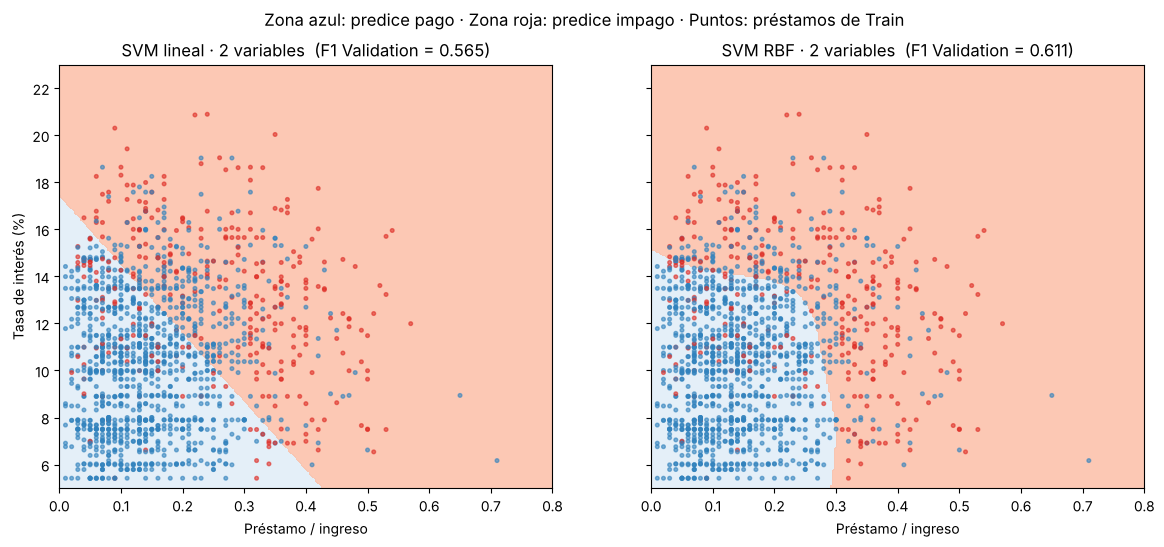

In [38]:
DOS_CR = ["loan_percent_income", "loan_int_rate"]
svm_2 = {}
for nombre, kernel in [("SVM lineal · 2 variables", "linear"), ("SVM RBF · 2 variables", "rbf")]:
    svm_2[nombre] = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                              ("model", SVC(kernel=kernel, C=1, gamma="scale", class_weight="balanced"))]).fit(X_train_cr[DOS_CR], y_train_cr)

gx, gy = np.meshgrid(np.linspace(0, 0.8, 250), np.linspace(5, 23, 250))
malla_cr = pd.DataFrame({"loan_percent_income": gx.ravel(), "loan_int_rate": gy.ravel()})
puntos = X_train_cr[DOS_CR].assign(y=y_train_cr).dropna().sample(1500, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (nombre, modelo) in zip(axes, svm_2.items()):
    zona = modelo.predict(malla_cr).reshape(gx.shape)
    ax.contourf(gx, gy, zona, levels=[-0.5, 0.5, 1.5], colors=["#deebf7", "#fcbba1"], alpha=0.8)
    ax.scatter(puntos["loan_percent_income"], puntos["loan_int_rate"], c=puntos["y"].map({0: "#3182bd", 1: "#de2d26"}), s=7, alpha=0.6)
    f1 = f1_score(y_val_cr, modelo.predict(X_val_cr[DOS_CR]))
    ax.set_title(f"{nombre}  (F1 Validation = {f1:.3f})")
    ax.set_xlabel("Préstamo / ingreso")
axes[0].set_ylabel("Tasa de interés (%)")
fig.suptitle("Zona azul: predice pago · Zona roja: predice impago · Puntos: préstamos de Train")
plt.show()
for nombre, modelo in svm_2.items():
    resultados_cr.append(resumen(y_val_cr, modelo.predict(X_val_cr[DOS_CR]), nombre))

**Lee el gráfico.** La SVM lineal traza una recta: por encima y a la derecha (préstamos grandes frente al ingreso y tasas altas) predice impago. La RBF puede **curvar** la frontera: reconoce, por ejemplo, que con una proporción del ingreso alta el impago es frecuente incluso con tasas moderadas. Con las mismas dos variables, la frontera curva mejora el F1 de Validation. Ninguna separa perfectamente: hay puntos rojos en la zona azul y viceversa.

### ¿Por qué probar una frontera lineal y otra curva?

Una SVM **lineal** divide el espacio de variables preparadas mediante una frontera recta (o un plano en más dimensiones). Si la relación entre columnas y respuesta es más compleja, esa frontera puede quedarse corta. El **kernel** es un procedimiento matemático que permite comparar préstamos en otra representación sin construir manualmente todas sus nuevas columnas; con el kernel **RBF** la frontera puede curvarse.

Esa flexibilidad también puede seguir el ruido de Train. En RBF, `gamma` controla qué tan **local** es la influencia de cada préstamo: valores grandes permiten cambios más rápidos cerca de los puntos; valores pequeños producen una influencia más extendida. Usaremos `gamma="scale"`, una regla automática de partida, no una prueba de que sea óptima. Compara primero lineal con RBF y después varios valores de `C`, siempre en Validation.

### ¿Cómo se curva la frontera? Un truco a mano

A veces ninguna recta separa las clases. En una variable estandarizada $x$, imagina impagos en los extremos (−3, −2,5, 2,5 y 3) y pagados en el centro (−1, −0,5, 0, 0,5 y 1). Un solo corte no alcanza. El truco: **agregar una columna nueva, $x^2$**. Los impagos pasan a 9 y 6,25; los pagados quedan entre 0 y 1. Ahora una recta separa: $x^2 = 3{,}6$. Vuelta a la variable original, esa recta equivale a dos cortes, $|x| > 1{,}9$: **una frontera curva**.

El **kernel** hace esto automáticamente, sin crear las columnas. El kernel **RBF** mide qué tan parecidos son dos préstamos (cerca de 1 si son casi iguales, cerca de 0 si están lejos) y con eso puede dibujar fronteras curvas; `gamma` decide qué tan lejos llega la influencia de cada punto.

In [39]:
x = np.array([-3, -2.5, -1, -0.5, 0, 0.5, 1, 2.5, 3])
clase = np.array(["impago", "impago", "pagado", "pagado", "pagado", "pagado", "pagado", "impago", "impago"])
print(pd.DataFrame({"x": x, "x al cuadrado": x ** 2, "clase": clase, "x² > 3,6": x ** 2 > 3.6}))

     x  x al cuadrado   clase  x² > 3,6
0 -3.0           9.00  impago      True
1 -2.5           6.25  impago      True
2 -1.0           1.00  pagado     False
3 -0.5           0.25  pagado     False
4  0.0           0.00  pagado     False
5  0.5           0.25  pagado     False
6  1.0           1.00  pagado     False
7  2.5           6.25  impago      True
8  3.0           9.00  impago      True


### Por qué SVM necesita cuidar las escalas y el desbalance

La posición de la frontera depende de los números con que representamos los préstamos. El ingreso, medido en decenas de miles, no debe imponerse automáticamente sobre la tasa de interés, medida en unidades. Por eso SVM, como KNN, recibe las variables numéricas escaladas en el Pipeline; las medias y desviaciones se aprenden **solo con Train**.

El código usa `class_weight="balanced"` porque hay muchos más préstamos pagados que impagos. Esto **aumenta el peso de los errores de la clase minoritaria durante el ajuste**, no fabrica más impagos ni garantiza mejor Recall o F1. Podría aumentar el número de alertas positivas y, con él, los falsos positivos. Después de entrenar, la matriz y las métricas dirán qué ocurrió realmente.

## C.4 El hiperparámetro `C`: el más importante de SVM

En los datos reales los préstamos pagados e impagos **se mezclan**: ninguna frontera separa todos. SVM tiene que elegir entre dos objetivos que compiten:

- un **margen ancho** (una «calle» amplia entre las clases), que hace la frontera más estable ante préstamos nuevos;
- **pocos errores en Train** (pocos préstamos del lado equivocado o dentro de la calle).

`C` decide cuánto castigar cada error de Train. Piénsalo como **la multa por cada préstamo mal clasificado en Train**:

| `C` | Multa por error | Qué hace la SVM | Riesgo |
|---|---|---|---|
| Pequeño (0,01 – 0,1) | Baja | Prefiere un margen ancho y tolera muchos errores: frontera suave y simple | **Subajuste**: demasiado simple |
| Intermedio (≈ 1) | Media | Equilibra margen y errores | — |
| Grande (10 – 100) | Alta | Se dobla para clasificar bien casi cada préstamo de Train: margen estrecho | **Sobreajuste**: memoriza Train |

`C` cumple en SVM el mismo papel que `max_depth` en el árbol o `k` en KNN: controla la complejidad. Por eso **siempre se elige comparando en Validation**. Con kernel RBF, `gamma` actúa junto con `C`; aquí lo dejamos en `"scale"` para estudiar solo `C`.

Probemos cinco valores de `C` con la SVM RBF (y `class_weight="balanced"`), y midamos F1 en Train y en Validation y el número de vectores de soporte.

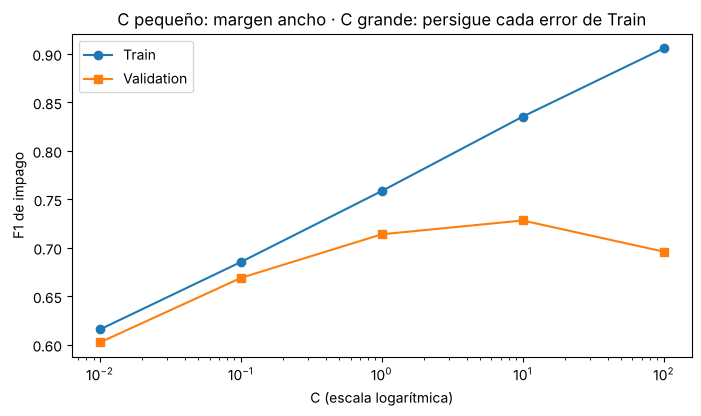

,C,f1_train,f1_validation,precision,recall,vectores_soporte
0,0.01,0.616,0.602,0.498,0.761,6192
1,0.10,0.685,0.669,0.605,0.749,4503
2,1.00,0.759,0.714,0.678,0.754,3698
3,10.00,0.835,0.728,0.716,0.741,3247
4,100.00,0.906,0.696,0.673,0.721,2799


In [40]:
filas_c = []
for valor_c in [0.01, 0.1, 1, 10, 100]:
    m = Pipeline([("prep", pre_svm),
                  ("model", SVC(kernel="rbf", C=valor_c, gamma="scale", class_weight="balanced"))]).fit(X_train_cr, y_train_cr)
    pv = m.predict(X_val_cr)
    filas_c.append({"C": valor_c, "f1_train": f1_score(y_train_cr, m.predict(X_train_cr)), "f1_validation": f1_score(y_val_cr, pv),
                    "precision": precision_score(y_val_cr, pv), "recall": recall_score(y_val_cr, pv),
                    "vectores_soporte": int(m.named_steps["model"].n_support_.sum())})
tabla_c = pd.DataFrame(filas_c)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tabla_c["C"], tabla_c["f1_train"], marker="o", label="Train")
ax.plot(tabla_c["C"], tabla_c["f1_validation"], marker="s", label="Validation")
ax.set_xscale("log"); ax.set_xlabel("C (escala logarítmica)"); ax.set_ylabel("F1 de impago"); ax.legend()
ax.set_title("C pequeño: margen ancho · C grande: persigue cada error de Train")
plt.show()
tabla_c.round(3)

**Interpretación.** Con `C` muy pequeño la SVM es demasiado tolerante: unos tres de cada cuatro préstamos de Train quedan dentro del margen (más de 6 000 vectores de soporte) y el F1 es bajo en ambos conjuntos. Al subir `C` mejora en Train y en Validation. Con `C` grande el F1 de Train sigue subiendo, pero el de Validation deja de mejorar o baja: la brecha crece y la frontera empieza a memorizar. El número de vectores de soporte baja al subir `C` porque la calle se hace más estrecha. **El mejor `C` está en la zona intermedia y se elige en Validation, nunca en Test.**

## C.5 SVM con todas las variables: kernel, `C` y `class_weight`

Ahora comparamos una frontera lineal, tres valores de `C` con RBF y una RBF sin `class_weight`. También medimos F1 en **Train**, para ver si alguna se ajusta demasiado.

In [41]:
modelos_svm = {}
for nombre, kernel, C, peso in [("SVM lineal, C=1", "linear", 1, "balanced"),
                                ("SVM RBF, C=0.5", "rbf", 0.5, "balanced"),
                                ("SVM RBF, C=1", "rbf", 1, "balanced"),
                                ("SVM RBF, C=2", "rbf", 2, "balanced"),
                                ("SVM RBF, C=1, sin class_weight", "rbf", 1, None)]:
    modelos_svm[nombre] = Pipeline([("prep", pre_svm),
                                    ("model", SVC(kernel=kernel, C=C, gamma="scale", class_weight=peso))]).fit(X_train_cr, y_train_cr)
filas_svm = []
for nombre, modelo in modelos_svm.items():
    fila = resumen(y_val_cr, modelo.predict(X_val_cr), nombre)
    fila["f1_train"] = f1_score(y_train_cr, modelo.predict(X_train_cr))
    fila["vectores_soporte"] = int(modelo.named_steps["model"].n_support_.sum())
    filas_svm.append(fila)
tabla_svm = pd.DataFrame(filas_svm).set_index("modelo")
print(tabla_svm.round(3))
pd.DataFrame([conteos(y_val_cr, m.predict(X_val_cr), n) for n, m in modelos_svm.items()]).set_index("modelo")

                                accuracy  precision_pos  recall_pos  f1_pos  \
modelo                                                                        
SVM lineal, C=1                    0.814          0.559       0.723   0.631   
SVM RBF, C=0.5                     0.860          0.656       0.759   0.704   
SVM RBF, C=1                       0.868          0.678       0.754   0.714   
SVM RBF, C=2                       0.872          0.697       0.731   0.714   
SVM RBF, C=1, sin class_weight     0.905          0.911       0.627   0.743   

                                f1_train  vectores_soporte  
modelo                                                      
SVM lineal, C=1                    0.648              4038  
SVM RBF, C=0.5                     0.736              3888  
SVM RBF, C=1                       0.759              3698  
SVM RBF, C=2                       0.781              3539  
SVM RBF, C=1, sin class_weight     0.785              2629  


,VN,FP,FN,VP,alertas
modelo,,,,,
"SVM lineal, C=1",1181,225,109,285,510
"SVM RBF, C=0.5",1249,157,95,299,456
"SVM RBF, C=1",1265,141,97,297,438
"SVM RBF, C=2",1281,125,106,288,413
"SVM RBF, C=1, sin class_weight",1382,24,147,247,271


### Leer las variantes de SVM

1. **Lineal frente a RBF:** con todas las variables, la frontera curva vuelve a superar a la recta en F1.
2. **`C`:** al subirlo de 0,5 a 2, la SVM penaliza más los errores de Train: el F1 de Train sube más que el de Validation y la brecha crece, como vimos en C.4.
3. **`class_weight`:** sin balancear, la SVM emite menos alertas y casi todas aciertan (Precision alta), pero deja escapar más impagos (Recall menor). Con balanceo ocurre lo contrario. Es el mismo intercambio que vimos con el árbol en la Parte A.
4. **Vectores de soporte:** cuántos préstamos de Train sostienen la frontera. Son miles: muchos préstamos quedan cerca del límite o del lado equivocado.

### ¿Qué observaciones sostienen la frontera?

En la intuición geométrica, los **vectores de soporte** son puntos de Train cercanos al límite o relevantes para los errores permitidos. Si esos puntos cambiaran, la frontera podría moverse. Esto contrasta con KNN: KNN consulta distancias a los ejemplos guardados cada vez que recibe una fila nueva; SVM usa una frontera aprendida para decidir el lado de esa fila.

Con RBF, la frontera en las columnas originales puede ser difícil de dibujar o explicar como una regla sencilla. Por eso una mejora numérica debe acompañarse de una discusión de errores, costo y límites; no afirmes que la SVM descubrió una causa económica del impago.

## C.6 SVM funciona mucho mejor cuando las clases están bien separadas

SVM busca una frontera con un margen amplio. Si los préstamos pagados e impagos **se separan bien** con las variables que le damos, la frontera es clara y SVM rinde muy bien. Si las clases están **muy mezcladas**, ninguna frontera ayuda mucho. Compáralo con lo que ya vimos: con solo dos variables (proporción del ingreso y tasa) las clases se mezclaban bastante y el F1 rondaba 0,6; con todas las variables, en especial el grado del préstamo y la tasa, los grupos se separan mejor y el F1 sube.

Cuando los datos están bien separados, **otros modelos también rinden bien**. Comparemos con un árbol y un bosque sobre la misma muestra y la misma división.

In [42]:
pre_arbol_cr = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cr),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cr),
])
arbol_cr = Pipeline([("prep", pre_arbol_cr), ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42))]).fit(X_train_cr, y_train_cr)
bosque_cr = Pipeline([("prep", pre_arbol_cr), ("model", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                                                               random_state=42, n_jobs=-1))]).fit(X_train_cr, y_train_cr)
mejor_svm = tabla_svm["f1_pos"].idxmax()
pd.DataFrame([resumen(y_val_cr, baseline_cr.predict(X_val_cr), "Baseline"),
              resumen(y_val_cr, svm_2["SVM RBF · 2 variables"].predict(X_val_cr[DOS_CR]), "SVM RBF · solo 2 variables"),
              resumen(y_val_cr, modelos_svm[mejor_svm].predict(X_val_cr), mejor_svm + " · todas"),
              resumen(y_val_cr, arbol_cr.predict(X_val_cr), "Árbol (prof. 5) · todas"),
              resumen(y_val_cr, bosque_cr.predict(X_val_cr), "Random Forest · todas")]).set_index("modelo").round(3)

,accuracy,precision_pos,recall_pos,f1_pos
modelo,,,,
Baseline,0.781,0.000,0.000,0.000
SVM RBF · solo 2 variables,0.807,0.546,0.693,0.611
"SVM RBF, C=1, sin class_weight · todas",0.905,0.911,0.627,0.743
Árbol (prof. 5) · todas,0.906,0.924,0.619,0.742
Random Forest · todas,0.912,0.940,0.640,0.761


**Interpretación.** Con todas las variables, la mejor SVM, el árbol y el bosque quedan muy cerca en F1. Es la señal de un dataset **con clases bastante bien separadas**: en esas condiciones SVM funciona muy bien, y otros modelos también. La SVM con solo dos variables queda bastante por debajo porque con esas dos columnas las clases se mezclan más. Cuando leas un notebook público con resultados altos, pregunta siempre con qué baseline y con qué otros modelos se comparó, sobre qué filas.

## C.7 ¿En qué otros casos se usa SVM?

SVM es especialmente útil cuando hay **muchas columnas en relación con el número de filas** y cuando las clases se separan bien con una frontera (recta o curva). Algunos usos típicos:

- **Clasificación de textos:** spam o no spam, noticias por tema, opiniones positivas o negativas. Cada palabra es una columna y suele haber miles; SVM lineal funciona muy bien ahí.
- **Imágenes y escritura a mano:** reconocer dígitos en cheques o formularios escaneados.
- **Bioinformática y medicina:** clasificar muestras con miles de mediciones (genes) y pocos pacientes.
- **Riesgo y fraude con datasets medianos:** puntajes de crédito, detección de transacciones o accesos anómalos, cuando las clases se separan bien con las variables disponibles.
- **Clasificación de documentos financieros o regulatorios** a partir de su texto.

**Cuándo no conviene:** con cientos de miles o millones de filas (el entrenamiento se vuelve muy lento: por eso aquí usamos una muestra de 12 000), cuando se necesita explicar la decisión con reglas simples o cuando se requieren probabilidades directamente (SVC no las entrega por defecto).

# Parte D · Cierre: tres datasets, una forma de evaluar

## D.1 ¿Por qué no comparar F1 entre datasets?

Cada dataset tiene su propia **tasa base**: 8 % de fraudes en la muestra de PaySim (0,13 % en el archivo completo), 16 % de abandonos en BankChurners y 22 % de impagos en Credit Risk. El mismo F1 no significa lo mismo con 8 % que con 22 % de positivos, y cada problema tiene columnas distintas. Las comparaciones honestas son **dentro** de cada dataset, sobre las mismas filas de Validation.

In [43]:
tasas = pd.DataFrame({
    "dataset": ["PaySim (muestra)", "BankChurners", "Credit Risk"],
    "filas_validation": [len(y_val_pay), len(y_val_ch), len(y_val_cr)],
    "pct_positivos": [y_val_pay.mean() * 100, y_val_ch.mean() * 100, y_val_cr.mean() * 100],
    "accuracy_baseline": [accuracy_score(y_val_pay, pred_base_pay), accuracy_score(y_val_ch, baseline_ch.predict(X_val_ch)),
                          accuracy_score(y_val_cr, baseline_cr.predict(X_val_cr))],
}).set_index("dataset")
tasas.round(3)

,filas_validation,pct_positivos,accuracy_baseline
dataset,,,
PaySim (muestra),15063,8.518,0.915
BankChurners,1519,16.063,0.839
Credit Risk,1800,21.889,0.781


**Lee la tabla.** El baseline «siempre la clase mayoritaria» ya obtiene entre 78 % y 92 % de Accuracy sin aprender nada; en el archivo completo de PaySim llegaría a 99,87 %. Por eso, en clasificación desbalanceada, Accuracy sola nunca alcanza: mira Recall, Precision y F1 de la clase que te importa.

## Profundización: cambiar una decisión mediante un umbral

Algunos clasificadores producen primero una **señal numérica** (*score*) y aplican luego una regla para convertirla en clase. Esa regla puede decir: «si el score supera un **umbral**, devuelve `yes`; si no, `no`». Un score **no tiene por qué ser una probabilidad**. En la siguiente celda inventamos ocho respuestas reales y ocho scores entre 0 y 1 solo para ver cómo cambia la regla; **no** son scores calibrados ni predicciones de ninguno de los tres datasets.

Al **bajar** el umbral, normalmente más personas reciben `yes`: podemos encontrar más positivos reales (**sube Recall**), pero también crear más falsos positivos (**Precision puede bajar**). Al **subirlo**, emitimos menos alertas; podríamos equivocarnos menos entre ellas y dejar escapar más `yes`. Recorre los tres umbrales de la celda y revisa ambos cambios antes de pensar en un «mejor» número. En un uso real la regla se definiría con Validation y costos explícitos; nunca la modificaríamos porque Test dio un resultado decepcionante.

In [44]:
y_umbral_demo = np.array([0, 0, 1, 1, 1, 0, 1, 0])
score_demo = np.array([.10, .35, .40, .55, .70, .72, .88, .90])
for umbral in [.35, .50, .75]:
    pred_demo = (score_demo >= umbral).astype(int)
    print("umbral", umbral,
          "Precision", round(precision_score(y_umbral_demo, pred_demo, zero_division=0), 2),
          "Recall", round(recall_score(y_umbral_demo, pred_demo, zero_division=0), 2),
          "F1", round(f1_score(y_umbral_demo, pred_demo, zero_division=0), 2))

umbral 0.35 Precision 0.57 Recall 1.0 F1 0.73
umbral 0.5 Precision 0.6 Recall 0.75 F1 0.67
umbral 0.75 Precision 0.5 Recall 0.25 F1 0.33


## D.2 Fijar la regla antes del examen final

Regla didáctica: **en cada dataset, entre las variantes del algoritmo que estudiamos, elegimos la de mayor F1 en Validation**: una variante de árbol o bosque en PaySim, una configuración de KNN en BankChurners y una de SVM en Credit Risk. F1 combina Precision y Recall; no representa dinero ni tiempo de llamadas. Si una decisión real penalizara mucho más los falsos negativos, lo declararíamos **antes** de consultar Test.

## D.3 Evaluación final: abrir Test una sola vez

Aplicamos exactamente los Pipelines elegidos a cada Test, sin reajustarlos. Si cambiáramos algo después de mirar Test, Test se convertiría en otra Validation.

In [45]:
# candidatos_pay y tabla_pay se construyeron en la Parte A (A.9).
elegido_pay = tabla_pay["f1_pos"].idxmax()
elegido_ch = tabla_knn["f1_pos"].idxmax()
elegido_cr = tabla_svm["f1_pos"].idxmax()

finales = []
for dataset, nombre, modelo, Xv, yv, Xt, yt in [
        ("PaySim (muestra)", elegido_pay, candidatos_pay[elegido_pay], X_val_pay, y_val_pay, X_test_pay, y_test_pay),
        ("BankChurners", elegido_ch, modelos_knn[elegido_ch], X_val_ch[FEAT_KNN], y_val_ch, X_test_ch[FEAT_KNN], y_test_ch),
        ("Credit Risk", elegido_cr, modelos_svm[elegido_cr], X_val_cr, y_val_cr, X_test_cr, y_test_cr)]:
    for conjunto, X_, y_ in [("Validation", Xv, yv), ("Test", Xt, yt)]:
        fila = resumen(y_, modelo.predict(X_), nombre)
        fila.update({"dataset": dataset, "conjunto": conjunto})
        finales.append(fila)
pd.DataFrame(finales).set_index(["dataset", "modelo", "conjunto"]).round(3)

accuracy  \
dataset          modelo                         conjunto               
PaySim (muestra) Árbol                          Validation     0.948   
                                                Test           0.954   
BankChurners     KNN k=15 Manhattan             Validation     0.922   
                                                Test           0.928   
Credit Risk      SVM RBF, C=1, sin class_weight Validation     0.905   
                                                Test           0.904   

                                                            precision_pos  \
dataset          modelo                         conjunto                    
PaySim (muestra) Árbol                          Validation          0.806   
                                                Test                0.821   
BankChurners     KNN k=15 Manhattan             Validation          0.849   
                                                Test                0.876   
Credit Risk      SVM RBF, C=1, sin class_weight Validation          0.911   
                                                Test                0.907   

                                                            recall_pos  f1_pos  
dataset          modelo                         conjunto                        
PaySim (muestra) Árbol                          Validation       0.521   0.633  
                                                Test             0.534   0.647  
BankChurners     KNN k=15 Manhattan             Validation       0.623   0.719  
                                                Test             0.639   0.739  
Credit Risk      SVM RBF, C=1, sin class_weight Validation       0.627   0.743  
                                                Test             0.623   0.739

### ¿Cómo comparar Validation y Test?

Las dos filas de la tabla muestran **las mismas métricas**, pero sobre filas diferentes. Empieza por cuántos positivos se detectaron (Recall) y la calidad de las alertas (Precision); luego compara F1 y Accuracy. Si son parecidas, el resultado fue relativamente consistente **en esta división**. Si Test empeora, no concluyas sin más que el algoritmo «se dañó»: pueden influir las filas concretas elegidas, el pequeño número de positivos o diferencias entre grupos y periodos.

No vuelvas a escoger `k`, kernel, `C` o umbral buscando un Test más favorable. Además, como las filas se repartieron aleatoriamente, este Test **no simula un periodo futuro completo**. Para una campaña posterior necesitaríamos validar con datos posteriores y revisar qué información estaba disponible antes de cada llamada.

### ¿Y si cambia la proporción de positivos?

A la frecuencia de la clase positiva se le llama **tasa base**. Es justo lo que ocurre con PaySim: en la muestra el fraude es 8 %, pero en el archivo completo es 0,13 %. Con la tasa real, aunque el modelo detectara una fracción semejante de los positivos reales, muchas de sus alertas serían falsas y **Precision bajaría**. Por eso no debemos trasladar una cifra de estos datasets a otra población o fecha.

Un cambio en las características de las personas o en la frecuencia de las respuestas se llama **cambio de distribución** (*shift*). Un sistema aplicado tendría que comprobar periódicamente las entradas, la calidad de `y` y las métricas con datos nuevos.

# Parte E · ¿Para qué es mejor cada modelo?

Ningún algoritmo gana siempre. La elección depende de cuántos datos hay, de cómo se separan las clases, de si hay que **explicar** la decisión y de cuánto tiempo de cálculo se tiene.

| Modelo | Cómo decide | Fortalezas | Debilidades | Úsalo cuando… | Ejemplos en banca y economía |
|---|---|---|---|---|---|
| **Árbol de decisión** | Preguntas sí/no en cadena | Se explica con reglas; no necesita escalar; mezcla números y categorías | Inestable: cambia con pocas filas; memoriza si no se limita | Hay que justificar la decisión ante un comité o un cliente | Reglas de aprobación de crédito, primeras alertas de fraude, segmentar clientes |
| **Random Forest** | Muchos árboles que votan | Más estable y preciso que un árbol; pocas decisiones de preparación; mide importancia de variables | Menos explicable; más lento; ocupa más memoria | Importa más acertar que explicar regla por regla | Scoring de riesgo, predicción de abandono, detección de fraude con muchas variables |
| **KNN** | Consulta a los k casos más parecidos | Idea muy intuitiva; no supone una forma de la relación; sirve para recomendar «casos similares» | Obliga a escalar; lento al predecir con muchos datos; empeora con muchas columnas | Hay pocas variables bien elegidas y tiene sentido «parecerse» | Clientes similares para ofertas, imputar datos faltantes con casos parecidos, comparar empresas o países similares |
| **SVM** | Frontera con el mayor margen | Muy bueno con muchas columnas y clases bien separadas; frontera curva con kernel | Obliga a escalar; lento con muchas filas; difícil de explicar; elegir `C` y `gamma` | Dataset mediano y clases separables; muchas columnas (por ejemplo, texto) | Clasificar documentos o reclamos por texto, scoring de crédito con datasets medianos, detectar operaciones anómalas |

**En resumen:** si necesitas **explicar**, empieza por un árbol limitado; si necesitas **precisión** con muchas variables, prueba un Random Forest; si la idea de **«casos parecidos»** tiene sentido y hay pocas variables, KNN; si hay **muchas columnas** o las clases se separan bien con una frontera, SVM. Y en todos los casos: baseline, Validation, métricas de la clase que importa y Test una sola vez.

## Actividad autónoma y comprobación de aprendizaje

Sin volver a elegir mirando Test:

1. **Árbol (PaySim):** cambia `max_depth` y `min_samples_leaf` del árbol; anota hojas, Recall y Precision, y dibuja el árbol con `plot_tree`.
2. **KNN (BankChurners):** prueba `k=5`, `15` y `31` con y sin escalar; explica con la matriz cómo cambian **FP y FN**.
3. **SVM (Credit Risk):** repite la tabla de C.4 con kernel lineal y con `C=0,05`, `0,5`, `5` y `50`; mira la brecha entre F1 de Train y de Validation.
4. **Decisión:** si el tiempo para revisar alertas de fraude o solicitudes fuera limitado, ¿qué error priorizarías y qué modelo elegirías?

**Comprueba que puedes explicarlo sin código:** ¿qué representan filas y columnas de una matriz de confusión? ¿Por qué el baseline puede tener Accuracy alta y Recall cero? ¿Por qué eliminamos las columnas de saldo de PaySim y las columnas `Naive_Bayes`? ¿Qué significan VP, VN, FP y FN, y por qué «positivo» no significa «bueno»? ¿Qué es un dataset desbalanceado y cómo se trabaja con él? ¿Por qué KNN y SVM necesitan normalizar y cómo se normaliza? ¿Qué significa el margen de SVM y qué controla `C`? ¿Por qué Test no sirve para seguir escogiendo modelos? Recuerda que estos datos no describen clientes del Ecuador.